# Introduction and setup

## Portfolio Optimization Pipeline

This notebook implements the empirical pipeline of the thesis:

0. Exclusion criterion — the case of Tesla (TSLA)
1. Historical benchmark
2. Factor-based expected returns
3. Implied-volatility-based covariance
4. Hybrid covariance through shrinkage (incl. risk contribution by asset)
5. Efficient frontier robustness check
6. Selected portfolios
7. Final in-sample comparison
8. Rolling backtest on the factorial model
9. Stress tests on implied volatilities
10. Stability analysis (turnover, HHI/ENP over time, FF6 factor stability)

Plus an opening on ESG scores — descriptive scores, a rolling backtest under an ESG
minimum-score constraint, and a real-money translation of its cost — left unnumbered as
it lies outside the main methodological progression.

## Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import *

from optimization import optimize_max_sharpe

from data_utils import (
    load_or_fetch_prices,
    compute_returns,
    align_data
)

from Fama_French import (
    load_or_fetch_ff6_factors,
    build_ff6_regression_table,
    compute_naive_expected_returns,
    compute_factor_expected_returns,
    compare_expected_returns
)

from covariance import (
    compute_historical_covariance,
    compute_implied_covariance,
    compute_shrunk_implied_covariance
)

from implied_volatility import load_or_fetch_implied_vols

from unconstrained_example import closed_form_tangency_weights

from portfolio_builders import build_optimized_portfolio

from portfolio_metrics import (
    portfolio_summary,
    portfolio_exposure,
    hhi_normalized,
    effective_number_of_positions,
    risk_contribution_table,
    annualized_stats,
    rolling_sharpe_ratio,
    sortino_ratio,
    cumulative_return,
    drawdown_series,
    max_drawdown,
    weight_shift_metrics
)

from backtest import rolling_backtest, rolling_backtest_esg

from stress_test import apply_iv_shock, run_stress_scenario, get_stress_scenario_weights

from statistical_tests import ledoit_wolf_test, sharpe_ratio, sharpe_ratio_compounded

from efficient_frontier import compute_frontier_summary

from comparison import format_portfolio_metrics

from visualization import *
set_plot_style()

## Configuration

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
bounds = [(0, 0.30)] * len(TICKERS)

SHOW_FIGURES = True

print("Number of assets:", len(TICKERS))
print("Study period:", START_DATE, "to", END_DATE)
print("Target option maturity:", TARGET_DAYS, "days")

Number of assets: 19
Study period: 2015-01-01 to 2026-06-30
Target option maturity: 30 days


# Part 0: Exclusion Criterion — The Case of Tesla (TSLA)

Tesla is a natural candidate for inclusion alongside the other technology names studied here
(AAPL, MSFT, NVDA, GOOGL, META), and yet it is excluded from the investable universe throughout
this study. Before moving to the actual portfolio construction, we document why with three pieces
of evidence directly tied to the methodology used later in this notebook:

1. **Realized volatility** — TSLA's volatility level sits structurally above the rest of the
   universe, which matters specifically here because the covariance matrix used downstream blends
   historical and *implied*-volatility information (Part 3). An outlier of this magnitude would
   dominate the shrinkage grid and distort the risk decomposition for every other asset.
2. **Price path** — TSLA's cumulative return is driven by a small number of idiosyncratic,
   firm-specific episodes rather than the systematic factor exposures (market, size, value, etc.)
   that the Fama-French regression in Part 2 relies on to estimate expected returns. This makes
   its expected-return estimate unusually unstable across sub-periods.
3. **Valuation** — TSLA's earnings multiple does not align with either the technology peer group
   or the traditional automotive sector, suggesting it does not map cleanly onto any single factor
   profile used in the rest of the analysis.

*Note on Figure 3 (P/E):* yfinance's free data only exposes a handful of years of annual
fundamentals, not a full 2015-2026 history, so the valuation comparison below is a **current
snapshot** (trailing P/E, or forward P/E where trailing is unavailable) rather than a multi-year
time series.

*Reproducibility:* Figures 1-4 are generated by `tsla_exclusion.py`, a standalone script (not run
inline) — run `python tsla_exclusion.py` from a terminal to refresh the PNGs below with the latest
market data. Keeping this section out of the notebook's execution path avoids re-downloading 19
tickers of daily price history on every "Run All" and keeps the .ipynb file small.

## Figure 1: Realized Volatility Ranking and Persistence — TSLA vs Investable Universe

![Median Realized Volatility (2015-2026): TSLA vs Investable Universe](figures/tsla_realized_vol_ranking.png)

![Daily Rank of TSLA's Realized Volatility within the Universe](figures/tsla_vol_rank_over_time.png)

## Figure 2: Normalized Price — TSLA vs Universe Median (base 100, Jan. 2015)

![Normalized Price (base 100, Jan. 2015): TSLA vs Universe Median](figures/tsla_normalized_price_vs_universe.png)

## Figure 3: Valuation Snapshot — TSLA vs S&P 500 and Traditional Automakers

![TSLA Valuation vs S&P 500 and Traditional Automakers](figures/tsla_pe_vs_benchmarks.png)

## Figure 4 (additional): Debt/Equity Ratio — Tesla (TSLA)

*Note:* unlike Figures 1-3, the quarterly D/E ratios below are transcribed by hand from MacroTrends
rather than pulled programmatically, since neither yfinance nor a free API exposes a clean
multi-year balance-sheet history. Treat these as indicative — cross-check the exact figures against
Tesla's 10-K / 10-Q filings before citing them in the final write-up.

![Tesla, Inc. (TSLA) — Debt/Equity Ratio Evolution (2015-2026)](figures/tsla_debt_equity_ratio.png)

## Downlaod prices and returns

**Freezing price and factor data (added 2026-08-01).**

Two of the three market data sources used in this notebook — adjusted close prices
(Yahoo Finance) and monthly Fama-French 6-factor returns (Ken French's data library) — were
until now downloaded live on *every* execution, even though the sample window is fixed by
`START_DATE`/`END_DATE` in `config.py`. This turned out to matter: neither source is perfectly
stable across executions of the *same* fixed window — Yahoo occasionally revises historical
adjusted-close values (dividend/split reprocessing), and Ken French's library is periodically
restated even for already-published months. In practice, re-running this notebook a few weeks
apart, with no code change at all, silently shifted `mu_factor`, `Sigma_hist`, and every metric
downstream of them (asset rankings, weights, Sharpe ratios) — invalidating text already drafted
against an earlier run.

Only the implied volatility vector was protected from this (see the note further below): it is
frozen to a snapshot on first retrieval and reused afterwards, instead of drifting with the market
on every re-run. Prices and FF6 factors now follow the exact same pattern, via
`load_or_fetch_prices` and `load_or_fetch_ff6_factors`: on first run they fetch live and save a
snapshot (`prices_snapshot.csv`, `spy_prices_snapshot.csv`, `ff6_factors_snapshot.csv`); every
later run reloads that snapshot instead of re-fetching.

**These three files are now the single source of truth for every number in this study.** Delete
any of them to force one fresh live pull and re-freeze on a new date — the plan is to do this
exactly once more, in early September, right before the final write-up, and to re-check every
number quoted in the text against that last run.

In [3]:
prices = load_or_fetch_prices(
    tickers=TICKERS,
    start=START_DATE,
    end=END_DATE,
    interval="1mo",
    snapshot_path=PRICES_SNAPSHOT_PATH
)

returns = compute_returns(
    prices=prices,
    method=RETURN_METHOD
)

Prices loaded from frozen snapshot (Price snapshot retrieved on 2026-09-12 (start=2015-01-01, end=2026-06-30))


## Download and align Fama-French factors

In [4]:
ff6 = load_or_fetch_ff6_factors(
    start=START_DATE,
    end=END_DATE,
    snapshot_path=FF6_FACTORS_SNAPSHOT_PATH
)

data = align_data(
    returns=returns,
    factors=ff6
)

Fama-French factors loaded from frozen snapshot (Fama-French 6-factor snapshot retrieved on 2026-09-12 (start=2015-01-01, end=2026-06-30))


## Risk-free rate

In [5]:
risk_free_rate = (1 + data["RF"].mean()) ** FREQUENCY - 1
print(f"Annualized risk-free rate: {risk_free_rate:.2%}")

Annualized risk-free rate: 2.00%


In [ ]:
rf_annualized = (1 + data["RF"]) ** FREQUENCY - 1

fig, ax = plot_risk_free_rate(rf_annualized)
plt.savefig("figures/rf_plot.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

# Part 1: Historical benchmark

## Historical expected returns and covariance

In [6]:
mu_naive = compute_naive_expected_returns(
    data=data,
    tickers=TICKERS,
    annualize=True
)

Sigma_hist = compute_historical_covariance(returns=data[TICKERS])
mu_naive.sort_values(ascending=False)

NVDA     0.872864
AVGO     0.482478
CAT      0.344802
AMZN     0.314588
GOOGL    0.298509
AAPL     0.279808
MSFT     0.263554
META     0.262544
GS       0.237978
JPM      0.234588
BAC      0.193301
UNH      0.188594
JNJ      0.130683
CVX      0.128695
HON      0.127902
XOM      0.123809
KO       0.109190
PG       0.093533
PEP      0.077632
dtype: float64

## Illustration: sensitivity of the unconstrained portfolio to estimation errors

Before imposing the long-only constraint used for the rest of the study, we illustrate why the
explicit unconstrained solution to the mean-variance problem (cf. formula above) is rarely usable
as-is in practice — first on a 2-asset example with very high correlation, then on the full
19-asset universe.

### Two-asset approach: SPY vs IVV

Prices loaded from frozen snapshot (Price snapshot retrieved on 2026-09-12 (start=2015-01-01, end=2026-06-30))
rho = 0.999779

mu (annualized) =
SPY    0.1544
IVV    0.1543
dtype: float64

vol (annualized) =
SPY    0.1507
IVV    0.1508
dtype: float64

Sigma =
          SPY       IVV
SPY  0.022719  0.022718
IVV  0.022718  0.022727

Sigma^{-1} =
          SPY       IVV
SPY  99812.17 -99770.99
IVV -99770.99  99773.82

w* =
SPY    2.3857
IVV   -1.3857
dtype: float64

Gross exposure = 377.13%
$$ \Sigma =
\begin{pmatrix}
0.022719 & 0.022718 \\
0.022718 & 0.022727
\end{pmatrix}
\qquad
\Sigma^{-1} =
\begin{pmatrix}
99812.17 & -99770.99 \\
-99770.99 & 99773.82
\end{pmatrix} $$

Saved to spy_ivv_matrix.tex


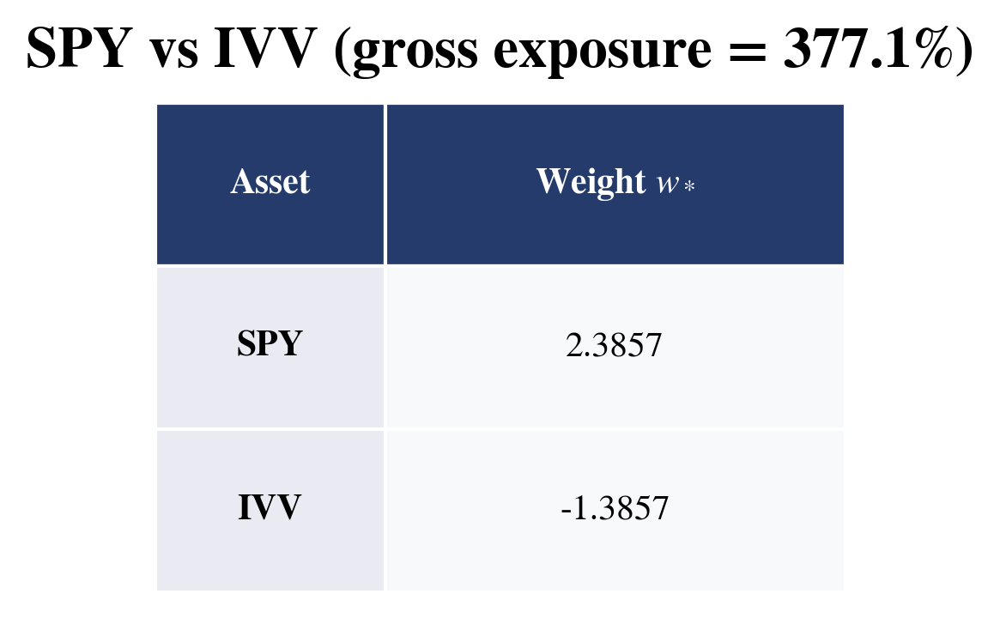

In [7]:
spy_ivv_prices = load_or_fetch_prices(
    tickers=["SPY", "IVV"],
    start=START_DATE,
    end=END_DATE,
    interval="1mo",
    snapshot_path=SPY_IVV_SNAPSHOT_PATH
)

spy_ivv_returns = compute_returns(prices=spy_ivv_prices, method=RETURN_METHOD)

rho_spy_ivv = spy_ivv_returns["SPY"].corr(spy_ivv_returns["IVV"])
mu_spy_ivv = compute_naive_expected_returns(data=spy_ivv_returns, tickers=["SPY", "IVV"], annualize=True)
Sigma_spy_ivv = compute_historical_covariance(returns=spy_ivv_returns[["SPY", "IVV"]])
Sigma_spy_ivv_inv = pd.DataFrame(
    np.linalg.inv(Sigma_spy_ivv.values),
    index=Sigma_spy_ivv.index,
    columns=Sigma_spy_ivv.columns
)
w_spy_ivv = closed_form_tangency_weights(mu_spy_ivv, Sigma_spy_ivv, risk_free_rate)
gross_exposure_spy_ivv = np.abs(w_spy_ivv.values).sum()

vol_spy_ivv = np.sqrt(np.diag(Sigma_spy_ivv.values))
vol_spy_ivv = pd.Series(vol_spy_ivv, index=Sigma_spy_ivv.index)

print(f"rho = {rho_spy_ivv:.6f}")
print("\nmu (annualized) =")
print(mu_spy_ivv.round(4))
print("\nvol (annualized) =")
print(vol_spy_ivv.round(4))
print("\nSigma =")
print(Sigma_spy_ivv.round(6))
print("\nSigma^{-1} =")
print(Sigma_spy_ivv_inv.round(2))
print("\nw* =")
print(w_spy_ivv.round(4))
print(f"\nGross exposure = {gross_exposure_spy_ivv:.2%}")

sigma_display = pd.DataFrame({
    r"$\Sigma_{SPY}$": Sigma_spy_ivv["SPY"].round(6),
    r"$\Sigma_{IVV}$": Sigma_spy_ivv["IVV"].round(6),
    r"$\Sigma^{-1}_{SPY}$": Sigma_spy_ivv_inv["SPY"].round(2),
    r"$\Sigma^{-1}_{IVV}$": Sigma_spy_ivv_inv["IVV"].round(2),
}, index=Sigma_spy_ivv.index)

"""
Native LaTeX matrix : better visual in a pdf.
"""
s = Sigma_spy_ivv.values
s_inv = Sigma_spy_ivv_inv.values

spy_ivv_matrix_tex = (
    r"$$ \Sigma =" "\n"
    r"\begin{pmatrix}" "\n"
    rf"{s[0,0]:.6f} & {s[0,1]:.6f} \\" "\n"
    rf"{s[1,0]:.6f} & {s[1,1]:.6f}" "\n"
    r"\end{pmatrix}" "\n"
    r"\qquad" "\n"
    r"\Sigma^{-1} =" "\n"
    r"\begin{pmatrix}" "\n"
    rf"{s_inv[0,0]:.2f} & {s_inv[0,1]:.2f} \\" "\n"
    rf"{s_inv[1,0]:.2f} & {s_inv[1,1]:.2f}" "\n"
    r"\end{pmatrix} $$" "\n"
)

with open("spy_ivv_matrix.tex", "w") as f:
    f.write(spy_ivv_matrix_tex)

print(spy_ivv_matrix_tex)
print("Saved to spy_ivv_matrix.tex")

weights_display = pd.DataFrame({r"Weight $w_*$": w_spy_ivv.round(4)}, index=w_spy_ivv.index)

fig = plot_combined_metrics_table(
    weights_display,
    table_groups={"Unconstrained tangency portfolio": [r"Weight $w_*$"]},
    title=rf"SPY vs IVV (gross exposure = {gross_exposure_spy_ivv:.1%})",
    index_label="Asset"
)
fig.savefig("figures/spy_ivv_weights_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

### Empirical experiment on the full portfolio

Same phenomenon on the full 19-asset universe: explicit unconstrained solution (short selling and
leverage allowed), using the same `mu_naive` and `Sigma_hist` as the constrained benchmark built
further below.

In [8]:
w_unconstrained = closed_form_tangency_weights(mu_naive, Sigma_hist, risk_free_rate)
w_unconstrained.name = "Unconstrained Portfolio"

summary_unconstrained = portfolio_summary(
    tickers=TICKERS,
    weights=w_unconstrained.values,
    mu=mu_naive,
    Sigma=Sigma_hist,
    risk_free_rate=risk_free_rate
)
summary_unconstrained

Expected Return                   52.500000
Volatility                        21.090000
Sharpe Ratio                       2.393798
HHI Normalized                     1.615701
Effective Number of Positions      0.631594
Long Exposure                    266.190000
Short Exposure                  -166.190000
Gross Exposure                   432.380000
Net Exposure                     100.000000
dtype: float64

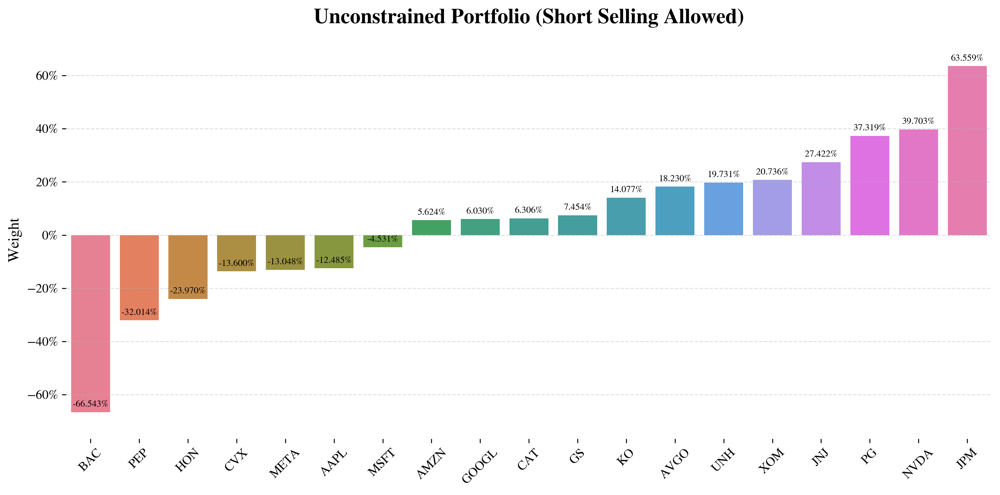

In [9]:
fig, ax = plot_weights(
    w_unconstrained,
    title="Unconstrained Portfolio (Short Selling Allowed)"
)

plt.savefig(
    "figures/unconstrained_portfolio_weights.png",
    dpi=300,
    bbox_inches="tight"
)

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

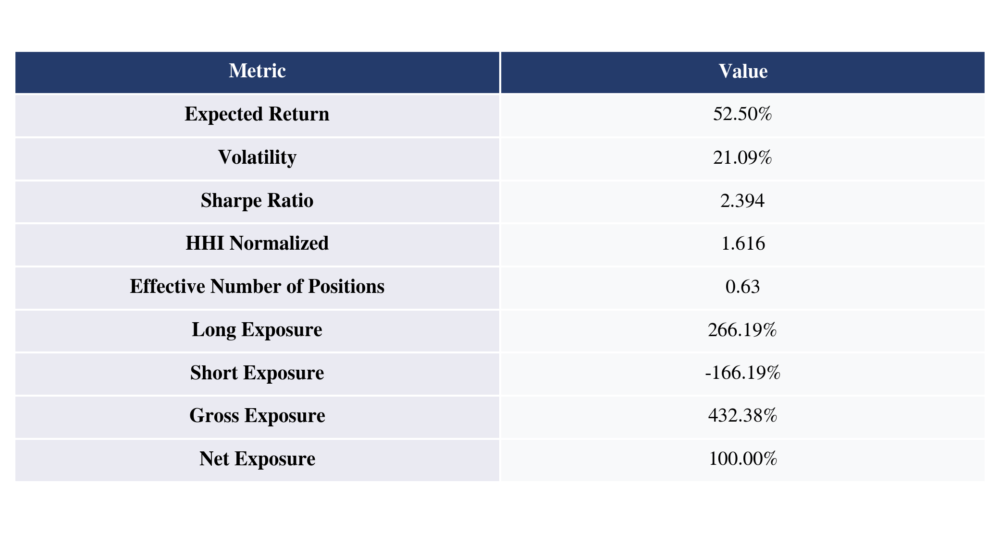

In [10]:
fig, ax = plot_portfolio_summary_table(
    summary_unconstrained,
    title=""
)

plt.savefig(
    "figures/unconstrained_summary.png",
    dpi=300,
    bbox_inches="tight"
)

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Correlation Matrix

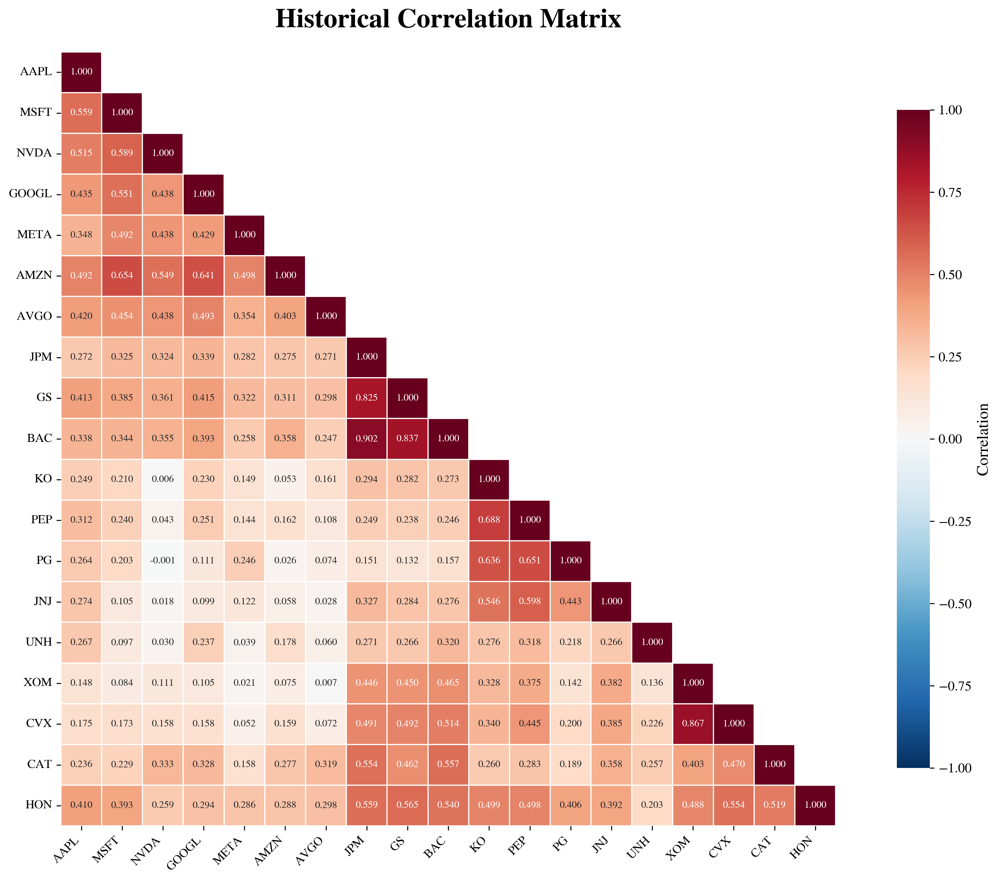

(<Figure size 4200x3000 with 2 Axes>,
 <Axes: title={'center': 'Historical Correlation Matrix'}>)

In [11]:
corr_matrix = data[TICKERS].corr()

plot_correlation_matrix(
    corr_matrix,
    title="Historical Correlation Matrix",
    annot=True,
    mask_upper=True,
    show=SHOW_FIGURES
)

## Historical benchmark portfolio

In [12]:
port_benchmark = optimize_max_sharpe(
    mu=mu_naive,
    Sigma=Sigma_hist,
    risk_free_rate=risk_free_rate,
    bounds=bounds
)

port_benchmark = pd.Series(
    port_benchmark,
    index=TICKERS,
    name="Benchmark Portfolio"
)

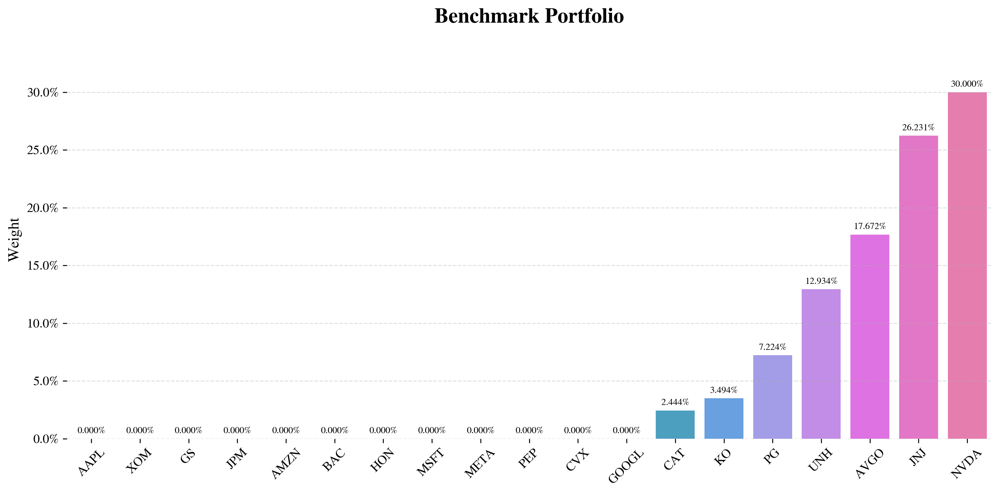

In [13]:
fig, ax = plot_weights(
    port_benchmark,
    title="Benchmark Portfolio"
)

plt.savefig(
    "figures/benchmark_weights.png",
    dpi=300,
    bbox_inches="tight"
)

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

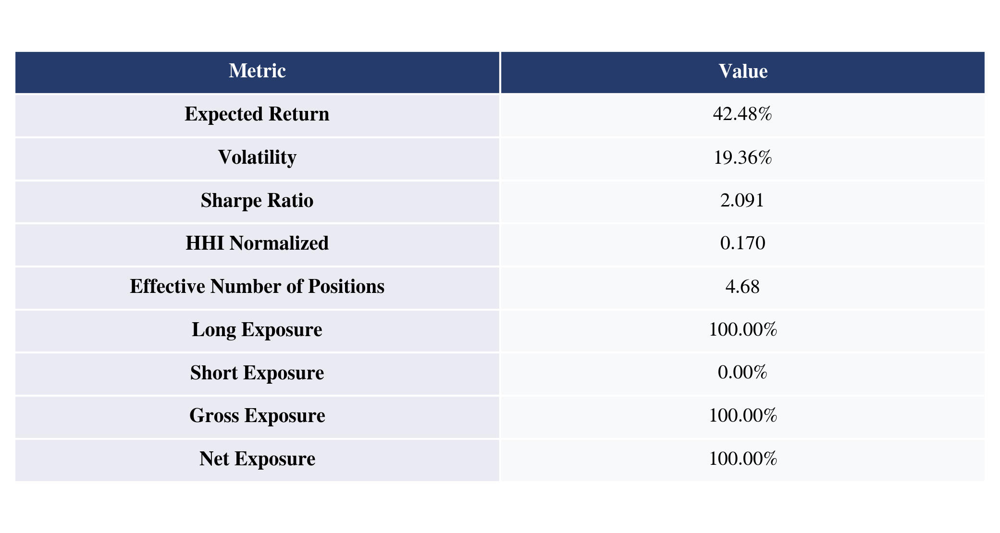

In [14]:
summary_benchmark = portfolio_summary(
    tickers=TICKERS,
    weights=port_benchmark.values,
    mu=mu_naive,
    Sigma=Sigma_hist,
    risk_free_rate=risk_free_rate
)

fig, ax = plot_portfolio_summary_table(
    summary_benchmark,
    title="",
    save_path="figures/benchmark_summary.png"
)

plt.savefig(
    "figures/benchmark_summary.png",
    dpi=300,
    bbox_inches="tight"
)

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Sanity check: naive equal-weight and passive benchmarks

A Sharpe ratio this high is far outside what any realistic passive strategy achieves — this is
the in-sample overfitting problem described in §1.2 made concrete. To show this explicitly, we
compare the optimized historical benchmark against two naive, non-optimized alternatives computed
over the **same period and the same monthly sample** as `data`:

1. An **equal-weighted portfolio** of the same 19 assets (no optimization at all).
2. A **passive S&P 500 ETF (SPY)** position, as a real-world market proxy.

If the optimized benchmark's Sharpe ratio dwarfs both of these, it confirms that the optimizer is
extracting noise from the estimation period rather than a genuinely achievable risk-adjusted
return.

Prices loaded from frozen snapshot (Price snapshot retrieved on 2026-09-12 (start=2015-01-01, end=2026-06-30))


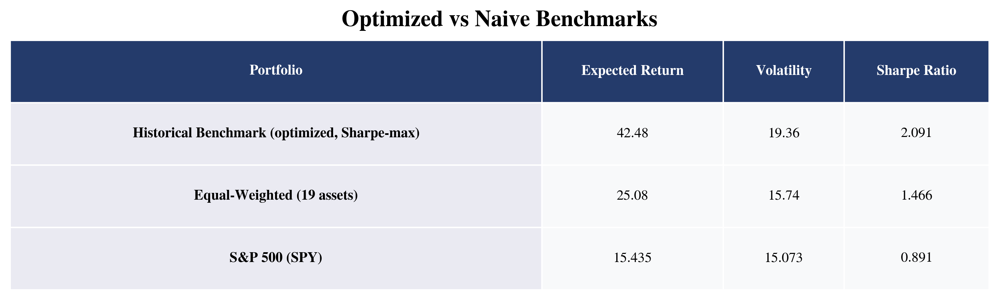

In [15]:
spy_prices = load_or_fetch_prices(
    tickers=["SPY"],
    start=START_DATE,
    end=END_DATE,
    interval="1mo",
    snapshot_path=SPY_PRICES_SNAPSHOT_PATH
)

spy_returns = compute_returns(
    prices=spy_prices,
    method=RETURN_METHOD
)

if isinstance(spy_returns, pd.DataFrame):
    spy_returns = spy_returns["SPY"]

spy_returns.index = pd.to_datetime(spy_returns.index).to_period("M")
spy_returns = spy_returns.reindex(data.index).dropna()

spy_return, spy_vol, spy_sharpe = annualized_stats(spy_returns, risk_free_rate)

"""
Equal-weight summary computed via the same theoretical convention (mu_naive / Sigma_hist, via portfolio_summary) 
as the optimized benchmark row above, rather than via annualized_stats on the realized return series. 
The two conventions are not interchangeable: annualizing each assets' mean return individually before combining (portfolio_summary) 
differs from combining monthly returns first and annualizing once (annualized_stats), because compounding is a convex transform. 
The gap is small for a diversified equal-weight portfolio but large for a concentrated one, 
see the Sharpe = 2.113 vs 1.941 gap for the optimized benchmark itself.  Keeping the same convention here as for the benchmark row 
is what makes the comparison table internally consistent.
"""
w_ew = np.ones(len(TICKERS)) / len(TICKERS)
summary_ew = portfolio_summary(
    tickers=TICKERS,
    weights=w_ew,
    mu=mu_naive,
    Sigma=Sigma_hist,
    risk_free_rate=risk_free_rate
)

naive_benchmark_comparison = pd.DataFrame({
    "Expected Return": [
        summary_benchmark["Expected Return"],
        summary_ew["Expected Return"],
        spy_return * 100
    ],
    "Volatility": [
        summary_benchmark["Volatility"],
        summary_ew["Volatility"],
        spy_vol * 100
    ],
    "Sharpe Ratio": [
        summary_benchmark["Sharpe Ratio"],
        summary_ew["Sharpe Ratio"],
        spy_sharpe
    ]
}, index=[
    "Historical Benchmark (optimized, Sharpe-max)",
    "Equal-Weighted (19 assets)",
    "S&P 500 (SPY)"
]).round(3)

fig = plot_combined_metrics_table(naive_benchmark_comparison,title="Optimized vs Naive Benchmarks")
fig.savefig("figures/naive_benchmark_metrics.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

# Part 2: Factor-based Expected Returns

## FF6 Regression

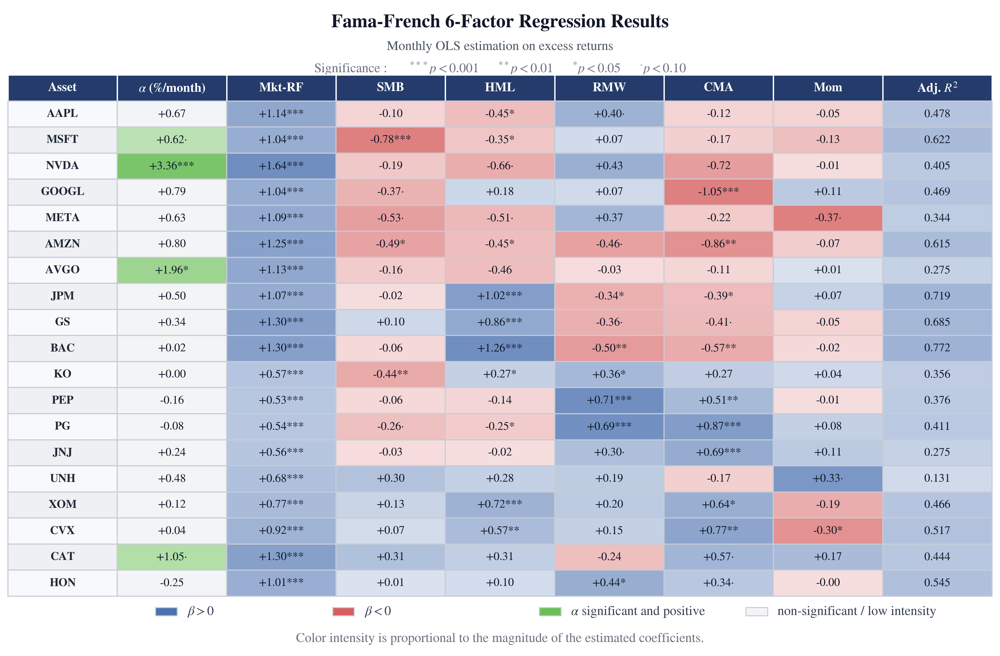

In [16]:
regression_table = build_ff6_regression_table(data=data,tickers=TICKERS)
fig = plot_factor_exposures(regression_table)

plt.savefig(
        "figures/ff6_factor_exposures.png",
        dpi=300,
        bbox_inches="tight"
    )

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Summary dashboard of average exposures

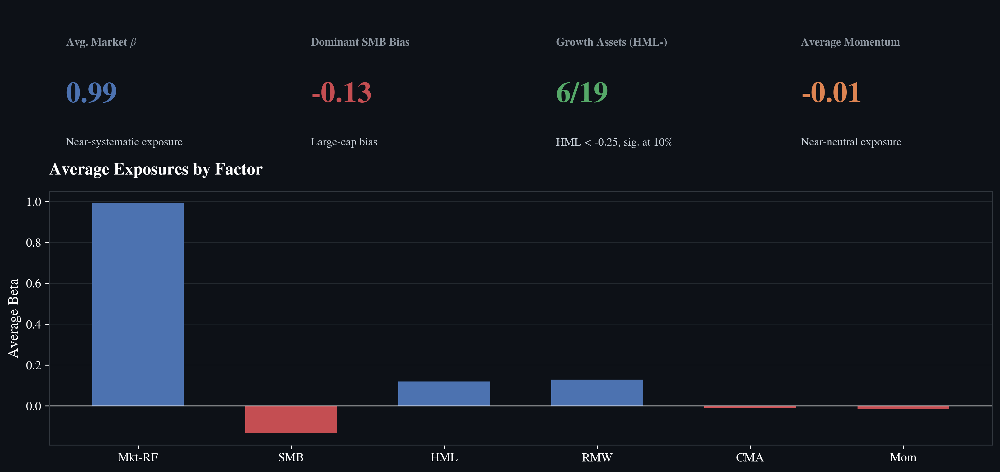

In [17]:
fig = plot_factor_exposure_dashboard(regression_table)

plt.savefig(
    "figures/ff6_factor_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Factor-based expected returns

In [18]:
mu_factor = compute_factor_expected_returns(
    data=data,
    regression_table=regression_table,
    annualize=True
)

expected_return_comparison = compare_expected_returns(
    mu_naive=mu_naive,
    mu_factor=mu_factor
)

expected_return_comparison.sort_values(
    "Factor-based",
    ascending=False
)

,Naive,Factor-based,Difference (Factor - Naive)
NVDA,0.872864,0.269289,-0.603574
AMZN,0.314588,0.196735,-0.117853
BAC,0.193301,0.190964,-0.002337
GS,0.237978,0.188993,-0.048985
CAT,0.344802,0.188105,-0.156696
GOOGL,0.298509,0.183227,-0.115283
AAPL,0.279808,0.183163,-0.096645
AVGO,0.482478,0.178485,-0.303993
MSFT,0.263554,0.173893,-0.089661
META,0.262544,0.171953,-0.090592


/Users/augustinloirat/Library/CloudStorage/GoogleDrive-augustin-21@hotmail.fr/Mon Drive/MBA/Memoire_Volatilite_Implicite/visualization.py:593: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


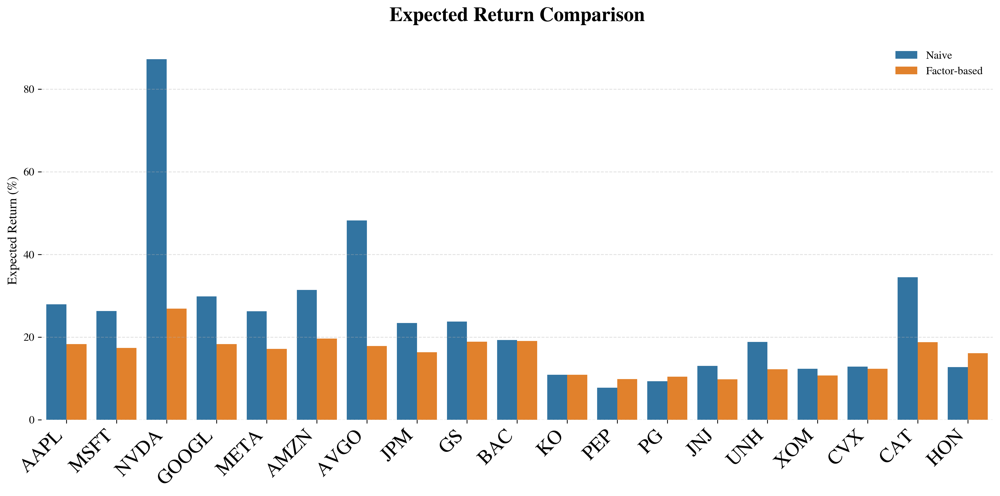

(<Figure size 4200x2100 with 1 Axes>,
 <Axes: title={'center': 'Expected Return Comparison'}, ylabel='Expected Return (%)'>)

In [19]:
plot_expected_return_comparison(expected_return_comparison, show=SHOW_FIGURES)

## Factor return + historical covariance portfolio

In [20]:
w_factor_hist = build_optimized_portfolio(
    tickers=TICKERS,
    mu=mu_factor,
    Sigma=Sigma_hist,
    risk_free_rate=risk_free_rate,
    name="Factor Return + Historical Covariance",
    bounds=bounds
)

w_factor_hist.sort_values(ascending=False).round(3)

PG       0.190
MSFT     0.128
KO       0.117
JPM      0.104
JNJ      0.095
HON      0.080
GOOGL    0.076
NVDA     0.059
UNH      0.051
AMZN     0.042
CAT      0.029
AAPL     0.015
AVGO     0.013
CVX      0.000
PEP      0.000
META     0.000
GS       0.000
XOM      0.000
BAC      0.000
Name: Factor Return + Historical Covariance, dtype: float64

## Compare allocations: benchmark vs factor-based

Before comparing performance metrics, we look directly at how capital is reallocated when
switching from naive historical returns to factor-based expected returns (same historical
covariance `Sigma_hist` in both cases, so any difference in weights comes purely from the change
in $\mu$).

In [21]:
weights_comparison = pd.concat([
    port_benchmark.rename("Historical Benchmark"),
    w_factor_hist.rename("Factor Return + Historical Covariance")
], axis=1)

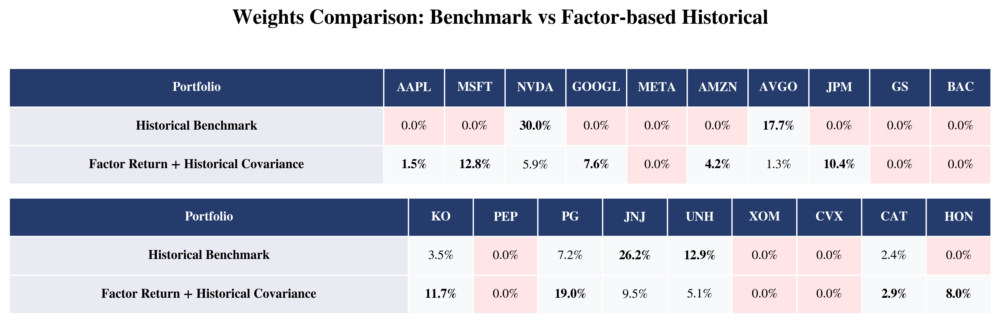

In [22]:
fig = plot_weights_table(
    weights_comparison,
    title="Weights Comparison: Benchmark vs Factor-based Historical"
)

fig.savefig("figures/weights_comparison_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Comparison: benchmark vs factor-based historical

We observe that the naive procedure gives way higher weights to the tech sector, due to the IA expansion from past years. The algorithm thinks that the past performances may reproduce in the future, a very hard and restrictive hypothesis that the factorial model tends to avoid, being way more reserved on those allocations.

# Part 3: Implied volatility and hybrid covariance

## Implied volatility vector

Implied volatilities are only available from yfinance's *current* live option chain (no
historical endpoint), so this snapshot is frozen to `implied_vols_snapshot.csv` on first
retrieval and reused on every later run, instead of silently drifting with the market each
time the notebook is re-executed. It was frozen close to `END_DATE` (2026-06-01), so it stays
temporally consistent with the historical sample used for the rest of the study. Delete the
snapshot file to force a fresh live pull.

In [23]:
implied_vols = load_or_fetch_implied_vols(
    tickers=TICKERS,
    risk_free_rate=risk_free_rate,
    target_days=TARGET_DAYS,
    snapshot_path=IMPLIED_VOLS_SNAPSHOT_PATH
)

implied_vols

Implied volatilities loaded from frozen snapshot (Implied volatility snapshot retrieved on 2026-09-12)


Ticker
AAPL     0.261085
MSFT     0.265365
NVDA     0.336554
GOOGL    0.302073
META     0.386580
AMZN     0.326512
AVGO     0.364059
JPM      0.247801
GS       0.361967
BAC      0.282299
KO       0.181314
PEP      0.272201
PG       0.206331
JNJ      0.270459
UNH      0.349542
XOM      0.319679
CVX      0.283578
CAT      0.362898
HON      0.273641
Name: Implied Volatility, dtype: float64

## Check missing implied volatilities

In [24]:
missing_iv = implied_vols[implied_vols.isna()]

if len(missing_iv) > 0:
    print("Missing implied volatility for:")
    print(missing_iv.index.tolist())
else:
    print("No missing implied volatility.")

No missing implied volatility.


## Optional fallback for missing implied volatilities

In [25]:
hist_vols = data[TICKERS].std() * np.sqrt(FREQUENCY)

implied_vols_filled = implied_vols.copy()
implied_vols_filled = implied_vols_filled.fillna(hist_vols)

iv_table = pd.DataFrame({
    "Historical Volatility": hist_vols,
    "Implied Volatility": implied_vols,
    "Implied Volatility Filled": implied_vols_filled
})

## Implied covariance matrix (hybrid)

In [26]:
Sigma_impl = compute_implied_covariance(
    returns=data[TICKERS],
    implied_vols=implied_vols_filled
)

# Part 4: $\lambda$ grid analysis (Shrinkage)

## $\lambda$ grid optimisation

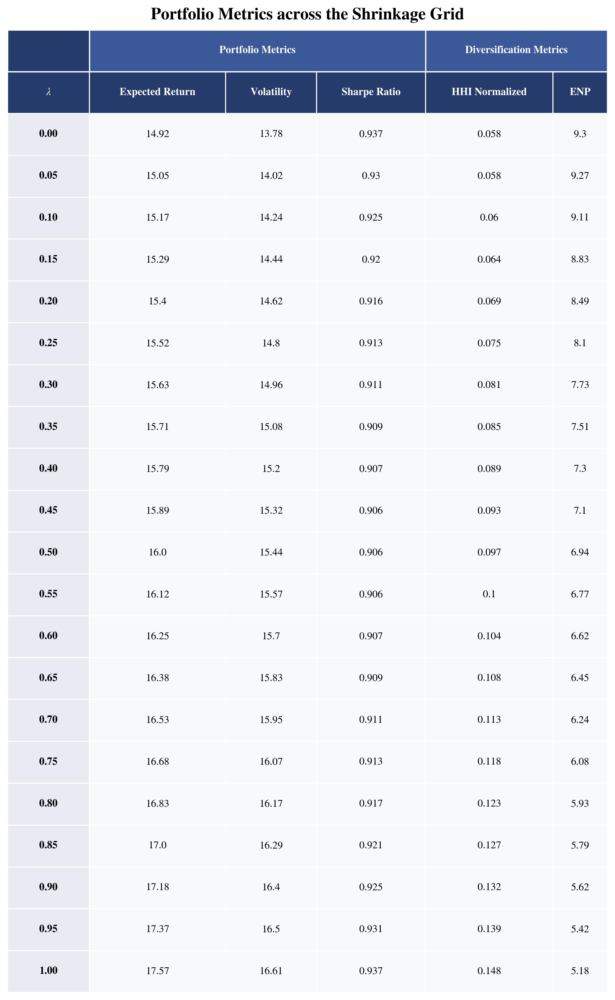

In [27]:
lambda_grid = np.round(np.arange(0, 1.05, 0.05), 2)  # np.arange leaves FP noise like 0.30000000000000004

lambda_results = []
lambda_weights = {}
lambda_sigmas = {}

for lambda_ in lambda_grid:
    Sigma_lambda = compute_shrunk_implied_covariance(
        returns=data[TICKERS],
        implied_vols=implied_vols_filled,
        lambda_=lambda_
    )

    w_lambda = build_optimized_portfolio(
        tickers=TICKERS,
        mu=mu_factor,
        Sigma=Sigma_lambda,
        risk_free_rate=risk_free_rate,
        name=f"Lambda {lambda_:.2f}",
        bounds=bounds
    )

    summary_lambda = portfolio_summary(
        tickers=TICKERS,
        weights=w_lambda.values,
        mu=mu_factor,
        Sigma=Sigma_lambda,
        risk_free_rate=risk_free_rate
    )

    summary_lambda["Lambda"] = lambda_

    lambda_results.append(summary_lambda)
    lambda_weights[f"{lambda_:.2f}"] = w_lambda
    lambda_sigmas[f"{lambda_:.2f}"] = Sigma_lambda

lambda_metrics = pd.DataFrame(lambda_results).set_index("Lambda")
lambda_weights = pd.DataFrame(lambda_weights)

lambda_metrics_formatted = format_portfolio_metrics(lambda_metrics)
lambda_metrics_formatted.index = [f"{l:.2f}" for l in lambda_metrics_formatted.index]

fig = plot_combined_metrics_table(
    lambda_metrics_formatted,
    table_groups={
        "Portfolio Metrics": ["Expected Return", "Volatility", "Sharpe Ratio"],
        "Diversification Metrics": ["HHI Normalized", "Effective Number of Positions"]
    },
    column_labels={"Effective Number of Positions": "ENP"},
    title="Portfolio Metrics across the Shrinkage Grid",
    index_label=r"$\lambda$"
)

fig.savefig("figures/lambda_metrics_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

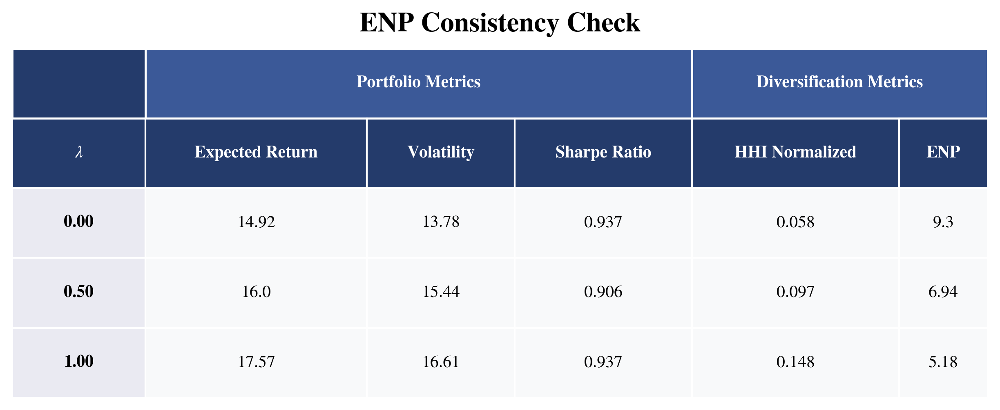

In [28]:
check_lambdas = [0.00, 0.50, 1.00]
enp_check = lambda_metrics.loc[check_lambdas, ["Expected Return", "Volatility", "Sharpe Ratio", "HHI Normalized", "Effective Number of Positions"]]
enp_check_formatted = format_portfolio_metrics(enp_check)
enp_check_formatted.index = [f"{l:.2f}" for l in enp_check_formatted.index]

fig = plot_combined_metrics_table(
    enp_check_formatted,
    table_groups={
        "Portfolio Metrics": ["Expected Return", "Volatility", "Sharpe Ratio"],
        "Diversification Metrics": ["HHI Normalized", "Effective Number of Positions"]
    },
    column_labels={"Effective Number of Positions": "ENP"},
    title="ENP Consistency Check",
    index_label=r"$\lambda$"
)
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)


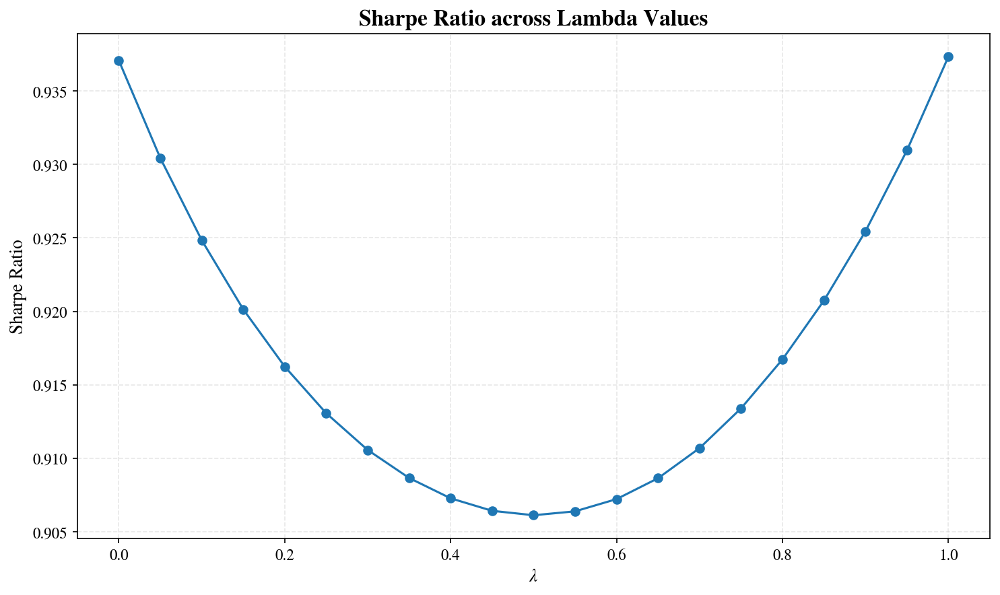

In [29]:
fig = plot_sharpe_across_lambda(lambda_metrics)
fig.savefig("figures/sharpe_ratio_across_lambda.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Sharpe ratio across lambda: comparison across two implied-vol snapshot dates

Illustrates the sensitivity of the lambda-grid Sharpe trajectory to the exact date the implied-vol snapshot was taken, by comparing the current live snapshot against the archived snapshot from the initial data freeze.

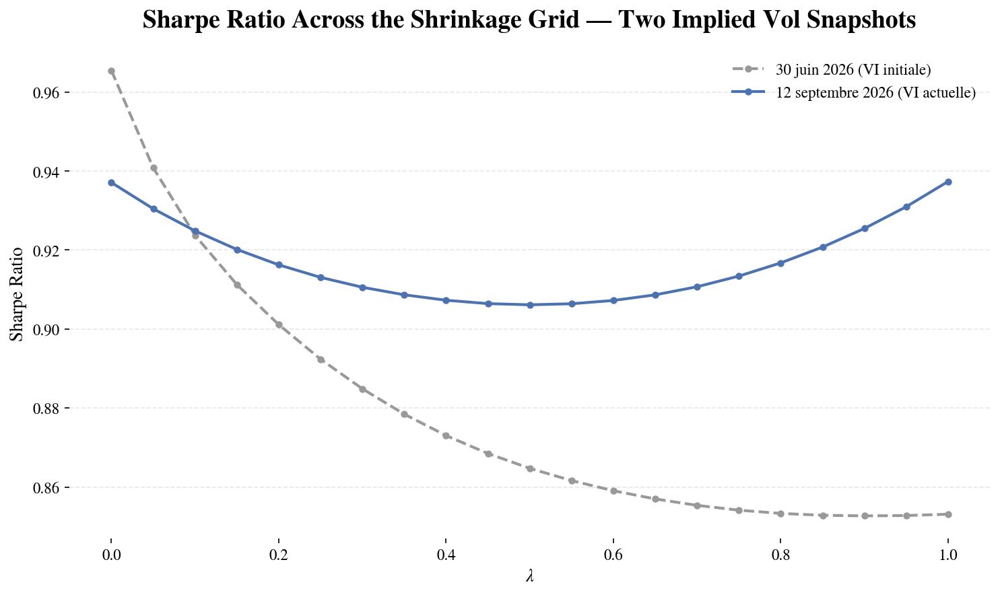

In [30]:
fig = plot_sharpe_lambda_snapshot_comparison(
    lambda_metrics,
    archive_path="data/lambda_metrics_20260630_archive.json",
    current_label="12 septembre 2026 (VI actuelle)",
    archive_label="30 juin 2026 (VI initiale)"
)
fig.savefig("figures/sharpe_lambda_snapshot_comparison.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## HHI normed across $\lambda$

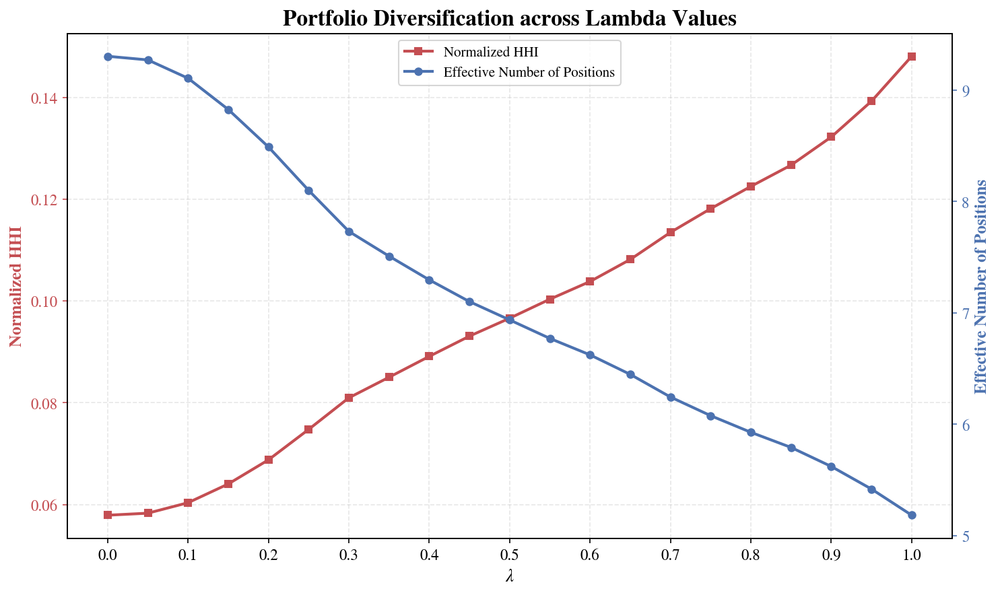

In [31]:
fig = plot_diversification_across_lambda(lambda_metrics)
fig.savefig("figures/diversification_metrics_across_lambda.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Selecting lambda objectively: elbow (Kneedle) detection

The choice of $\lambda = 0.25$ made above rests on a qualitative asymmetry argument (modest
Sharpe cost vs already-substantial diversification cost). To complement it with a reproducible,
parameter-free criterion, we locate the elbow of the Sharpe/diversification trade-off using the
Kneedle method: normalize both the Sharpe ratio and the diversification metric (ENP, or HHI) onto
a common `[0, 1]` "fraction retained" scale across the grid, then find the lambda where the gap
between the two normalized curves and the no-tradeoff diagonal is largest.

In [32]:
def retained(series):
    """Rescales a monotone series to 1 at lambda=0 (nothing lost) and 0 at lambda=1 (fully lost)."""
    return (series - series.iloc[-1]) / (series.iloc[0] - series.iloc[-1])

sharpe_retained = retained(lambda_metrics["Sharpe Ratio"])
enp_retained = retained(lambda_metrics["Effective Number of Positions"])
hhi_retained = retained(-lambda_metrics["HHI Normalized"])  # HHI grows with lambda, so sign-flip first

gap_enp = (sharpe_retained - enp_retained) / np.sqrt(2)
gap_hhi = (sharpe_retained - hhi_retained) / np.sqrt(2)

elbow_enp = gap_enp.idxmin()
elbow_hhi = gap_hhi.idxmin()
print(f"Elbow (Sharpe vs ENP): lambda = {elbow_enp}, gap = {gap_enp.min():.4f}")
print(f"Elbow (Sharpe vs HHI): lambda = {elbow_hhi}, gap = {gap_hhi.min():.4f}")

Elbow (Sharpe vs ENP): lambda = 0.0, gap = -0.0000
Elbow (Sharpe vs HHI): lambda = 0.0, gap = -0.0000


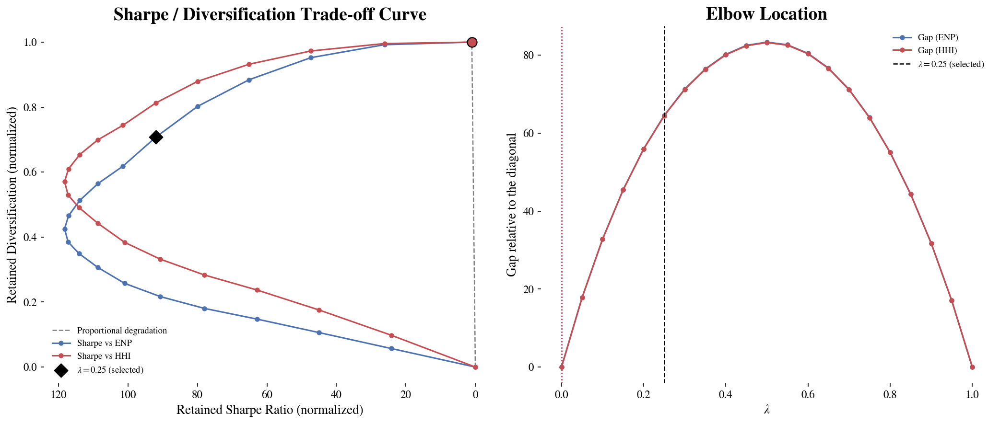

In [33]:
fig = plot_lambda_elbow_analysis(
    sharpe_retained, enp_retained, hhi_retained,
    gap_enp, gap_hhi, elbow_enp, elbow_hhi
)
fig.savefig("figures/lambda_elbow_analysis.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Weights across $\lambda$

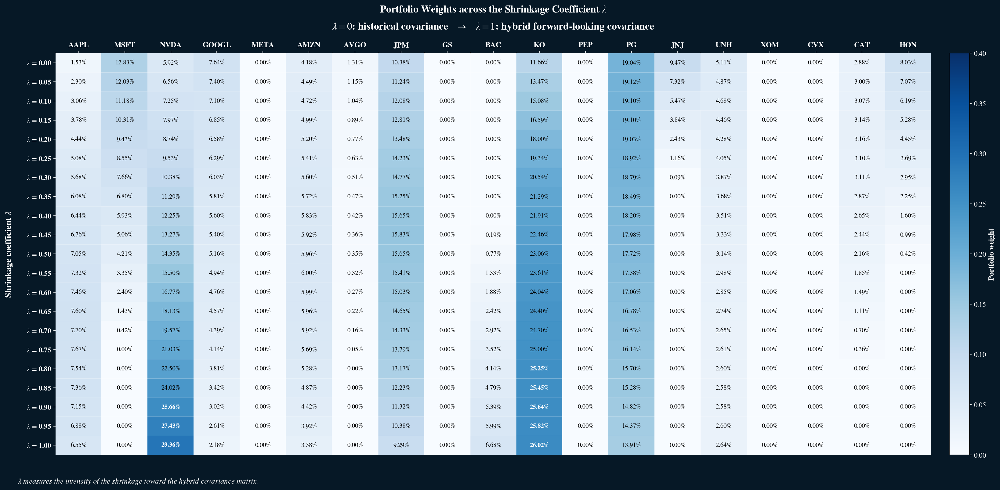

In [34]:
fig = plot_lambda_weights_heatmap(lambda_weights, TICKERS)
fig.savefig("figures/weights_lambda_heatmap.png", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Animated allocation across $\lambda$ (presentation asset)


In [35]:
anim = animate_lambda_weights(
    lambda_weights=lambda_weights,
    lambda_grid=lambda_grid,
    order_by="1.00",
    filename="figures/lambda_weights_animation.mp4"
)
print("Saved lambda_weights_animation.mp4")

Saved lambda_weights_animation.mp4


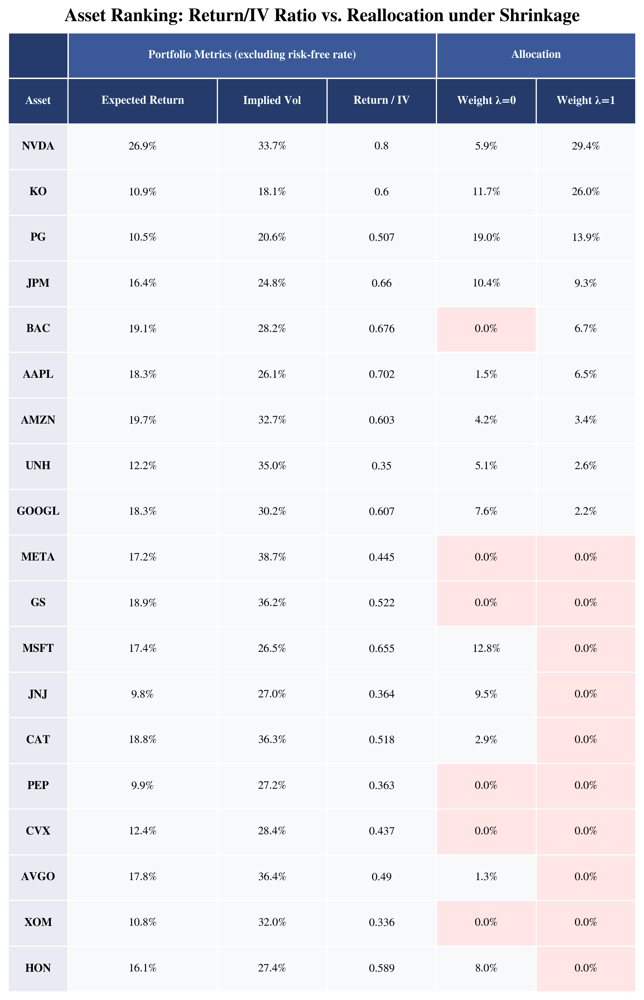

In [36]:
ranking_df = pd.DataFrame({
    "Expected Return": mu_factor,
    "Implied Vol": implied_vols_filled,
    "Return / IV": mu_factor / implied_vols_filled,
    "Weight λ=0": lambda_weights["0.00"],
    "Weight λ=1": lambda_weights["1.00"]
}).sort_values("Weight λ=1", ascending=False)

ranking_display = pd.DataFrame({
    "Expected Return": ranking_df["Expected Return"].mul(100).round(1).map(lambda v: f"{v:.1f}%"),
    "Implied Vol": ranking_df["Implied Vol"].mul(100).round(1).map(lambda v: f"{v:.1f}%"),
    "Return / IV": ranking_df["Return / IV"].round(3),
    "Weight λ=0": ranking_df["Weight λ=0"].mul(100).round(1).map(lambda v: f"{v:.1f}%"),
    "Weight λ=1": ranking_df["Weight λ=1"].mul(100).round(1).map(lambda v: f"{v:.1f}%")
})

fig = plot_combined_metrics_table(
    ranking_display,
    table_groups={
        "Portfolio Metrics (excluding risk-free rate)": ["Expected Return", "Implied Vol", "Return / IV"],
        "Allocation": ["Weight λ=0", "Weight λ=1"]
    },
    zero_highlight_columns=["Weight λ=0", "Weight λ=1"],
    title="Asset Ranking: Return/IV Ratio vs. Reallocation under Shrinkage",
    index_label="Asset"
)

fig.savefig("figures/ranking_weights_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Risk contribution across $\lambda$

The shrinkage analysis above shows *how much* weight each asset receives as $\lambda$ varies, but
not *why* the optimizer moves capital around. A weight can stay flat while the risk it carries
changes a lot, or vice-versa. The risk contribution of asset $i$ decomposes total portfolio
variance additively:

$$ RC_i = w_i \times \frac{(\Sigma w)_i}{\sigma_p} \qquad \text{with} \qquad \sum_{i=1}^n RC_i = \sigma_p $$

To avoid cherry-picking a few arbitrary $\lambda$ values, we compute this decomposition across
the **same full $\lambda$ grid** used throughout this section (21 steps from 0 to 1), reusing the
weights already obtained above. This tells us whether the hybrid covariance reshapes the
portfolio by redistributing *risk* budget (not just capital) toward the assets whose implied
volatility is comparatively low relative to their correlation structure.

In [37]:
risk_contrib_grid = pd.DataFrame(
    index=[f"{lambda_:.2f}" for lambda_ in lambda_grid],
    columns=TICKERS,
    dtype=float
)

for lambda_ in lambda_grid:
    label = f"{lambda_:.2f}"

    table = risk_contribution_table(
        tickers=TICKERS,
        weights=lambda_weights[label].values,
        Sigma=lambda_sigmas[label]
    )

    risk_contrib_grid.loc[label] = table["Risk Contribution (%)"].values

#risk_contrib_grid.round(3)

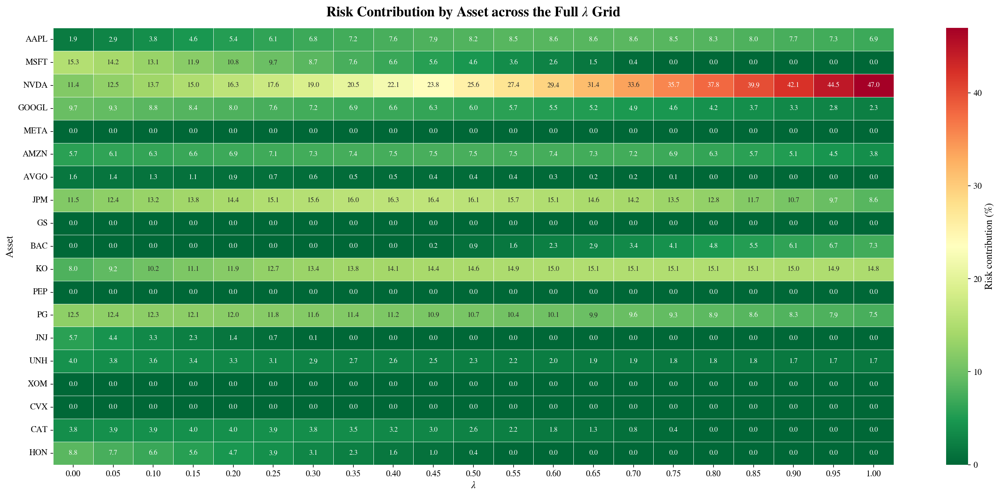

In [38]:
fig = plot_risk_contribution_heatmap(risk_contrib_grid)
fig.savefig("figures/risk_contribution_heatmap.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Focus on the fully hybrid portfolio ($\lambda=1$)

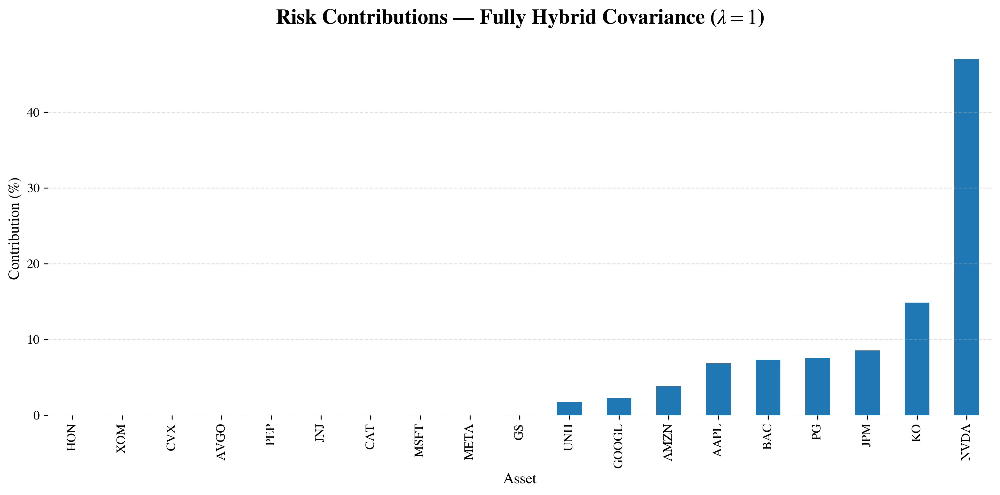

(<Figure size 3600x1800 with 1 Axes>,
 <Axes: title={'center': 'Risk Contributions — Fully Hybrid Covariance ($\\lambda=1$)'}, xlabel='Asset', ylabel='Contribution (%)'>)

In [39]:
rc_table_lambda1 = risk_contribution_table(
    tickers=TICKERS,
    weights=lambda_weights["1.00"].values,
    Sigma=lambda_sigmas["1.00"]
)

plot_risk_contributions(
    rc_table_lambda1,
    title="Risk Contributions — Fully Hybrid Covariance ($\\lambda=1$)",
    show=SHOW_FIGURES
)

## Select representative $\lambda$ values

Rather than picking a different ad hoc subset of $\lambda$ in each robustness check below, we fix
**one** representative set here and reuse it consistently for the efficient frontier (Part 5) and
the portfolio selection table (Part 6): the two endpoints and quartiles of the grid (0, 0.25, 0.5,
0.75, 1) as an even, non-arbitrary baseline, plus the empirically optimal points — the $\lambda$
that maximizes the Sharpe ratio and the one that minimizes concentration (normalized HHI).

In [40]:
best_lambda_sharpe = lambda_metrics["Sharpe Ratio"].idxmax()
best_lambda_hhi = lambda_metrics["HHI Normalized"].idxmin()

selected_lambdas = sorted(set([
    0.00,
    0.25,
    0.60,
    1.00,
    round(float(best_lambda_sharpe), 2),
    round(float(best_lambda_hhi), 2)
]))

# Part 5: Efficient frontier (robustness check)

So far we have only looked at *one point* per covariance matrix: the max-Sharpe (tangency)
portfolio returned by the optimizer. This section checks two things:

1. **Sanity check of the optimization** — the tangency portfolio found by `optimize_max_sharpe`
   should lie *on* the efficient frontier traced out by `optimize_target_return` across a grid of
   target returns. If it doesn't, something is wrong with either optimizer.
2. **Effect of the return/covariance methodology on the whole risk-return menu**, not just the
   single optimal point — moving from historical returns to factor-based returns, and from
   historical to (partially, then fully) implied covariance, does not just change which portfolio
   is "best", it reshapes the entire set of achievable (volatility, return) combinations.

We overlay five frontiers spanning the four stages of the methodology built up so far: the
historical benchmark ($\mu_{naive}$, $\Sigma_{hist}$), the same historical covariance corrected
with factor-based returns ($\mu_{factor}$, $\Sigma_{hist}$), two intermediate hybrid covariances
($\mu_{factor}$, $\Sigma_{\lambda=0.25}$ and $\mu_{factor}$, $\Sigma_{\lambda=0.60}$), and the
fully implied covariance ($\mu_{factor}$, $\Sigma_{\lambda=1}$) — reusing $\Sigma_{\lambda}$
matrices already cached in `lambda_sigmas` (Part 4), and the same long-only, 30%-per-asset
bounds as the rest of the analysis.

In [41]:
frontier_inputs = {
    "Historical Benchmark": (mu_naive, Sigma_hist),
    "FF6 Return + Historical Covariance": (mu_factor, Sigma_hist),
    r"FF6 Return + Hybrid ($\lambda$ = 0.25)": (mu_factor, lambda_sigmas["0.25"]),
    r"FF6 Return + Hybrid ($\lambda$ = 0.60)": (mu_factor, lambda_sigmas["0.60"]),
    r"FF6 Return + Implied ($\lambda$ = 1.00)": (mu_factor, lambda_sigmas["1.00"]),
}

frontier_summaries = {}

for label, (mu, Sigma) in frontier_inputs.items():
    frontier_summaries[label] = compute_frontier_summary(
        mu=mu,
        Sigma=Sigma,
        risk_free_rate=risk_free_rate,
        n_points=50,
        bounds=bounds
    )


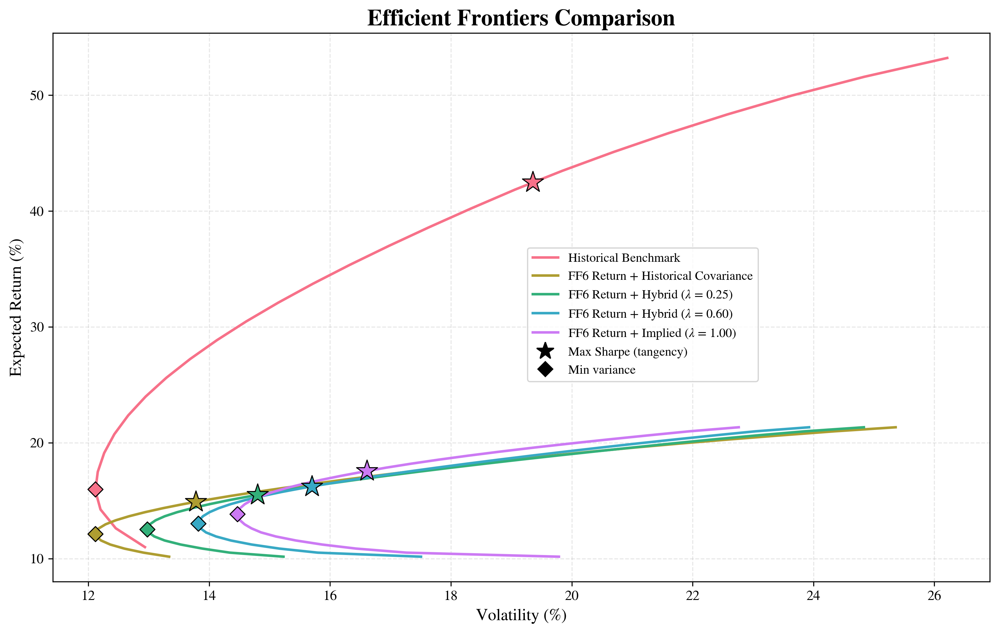

In [42]:
fig, ax = plot_efficient_frontier(
    frontier_summaries,
    title="Efficient Frontiers Comparison",
    legend_loc="upper left",
    legend_bbox_to_anchor=(0.50, 0.62)  # docked in the empty gap above the hybrid/implied cluster - nudge if it overlaps
)

plt.savefig(
    "figures/efficient_frontiers_lambda.png",
    dpi=300,
    bbox_inches="tight"
)

## Tangency and minimum variance portfolio metrics across methodologies

Return, volatility and Sharpe ratio of both the max-Sharpe (tangency) portfolio and the
minimum variance portfolio on each of the five frontiers above, so the exact numbers behind
the chart are also available as a compact table for the write-up.

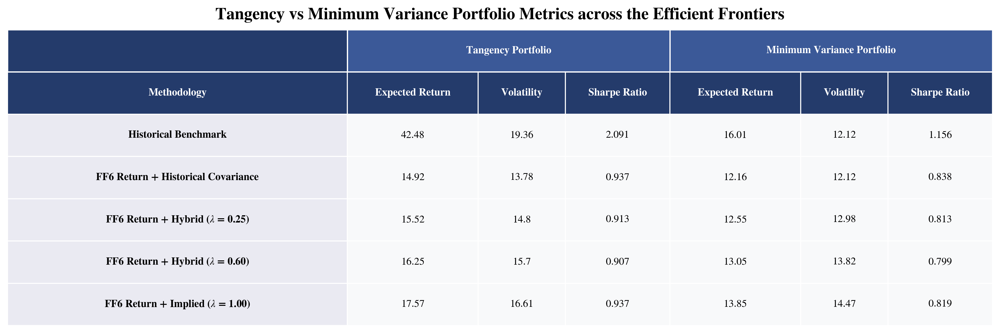

In [43]:
frontier_combined_metrics = pd.DataFrame({
    label: {
        "Expected Return (Tangency)": round(summary["tangent_return"] * 100, 2),
        "Volatility (Tangency)": round(summary["tangent_volatility"] * 100, 2),
        "Sharpe Ratio (Tangency)": round(summary["tangent_sharpe"], 3),
        "Expected Return (Min Variance)": round(summary["min_var_return"] * 100, 2),
        "Volatility (Min Variance)": round(summary["min_var_volatility"] * 100, 2),
        "Sharpe Ratio (Min Variance)": round(summary["min_var_sharpe"], 3),
    }
    for label, summary in frontier_summaries.items()
}).T

fig = plot_combined_metrics_table(
    frontier_combined_metrics,
    table_groups={
        "Tangency Portfolio": ["Expected Return (Tangency)", "Volatility (Tangency)", "Sharpe Ratio (Tangency)"],
        "Minimum Variance Portfolio": ["Expected Return (Min Variance)", "Volatility (Min Variance)", "Sharpe Ratio (Min Variance)"]
    },
    column_labels={
        "Expected Return (Tangency)": "Expected Return",
        "Volatility (Tangency)": "Volatility",
        "Sharpe Ratio (Tangency)": "Sharpe Ratio",
        "Expected Return (Min Variance)": "Expected Return",
        "Volatility (Min Variance)": "Volatility",
        "Sharpe Ratio (Min Variance)": "Sharpe Ratio",
    },
    title="Tangency vs Minimum Variance Portfolio Metrics across the Efficient Frontiers",
    index_label="Methodology"
)

fig.savefig("figures/frontier_tangency_metrics_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

# Part 6: Selected portfolios

## Representative $\lambda$ values

We reuse the `selected_lambdas` set defined at the end of Part 4 — the quartiles of the grid plus
the empirically optimal points — to keep one non-arbitrary reference set for the metrics and
weights below, independently of the four-methodology comparison shown in Part 5.

In [44]:
selected_metrics = lambda_metrics.loc[selected_lambdas]
format_portfolio_metrics(selected_metrics)

,Expected Return,Volatility,Sharpe Ratio,HHI Normalized,Effective Number of Positions,Long Exposure,Short Exposure,Gross Exposure,Net Exposure
Lambda,,,,,,,,,
0.00,14.92,13.78,0.937,0.058,9.30,100.0,0.0,100.0,100.0
0.25,15.52,14.80,0.913,0.075,8.10,100.0,0.0,100.0,100.0
0.60,16.25,15.70,0.907,0.104,6.62,100.0,0.0,100.0,100.0
1.00,17.57,16.61,0.937,0.148,5.18,100.0,0.0,100.0,100.0


## Select associated weights

In [45]:
selected_lambda_labels = [f"{lambda_:.2f}" for lambda_ in selected_lambdas]
selected_weights = lambda_weights[selected_lambda_labels]
selected_weights.round(3)

,0.00,0.25,0.60,1.00
AAPL,0.015,0.051,0.075,0.065
MSFT,0.128,0.085,0.024,0.000
NVDA,0.059,0.095,0.168,0.294
GOOGL,0.076,0.063,0.048,0.022
META,0.000,0.000,0.000,0.000
AMZN,0.042,0.054,0.060,0.034
AVGO,0.013,0.006,0.003,0.000
JPM,0.104,0.142,0.150,0.093
GS,0.000,0.000,0.000,0.000
BAC,0.000,0.000,0.019,0.067


# Part 7: Final in-sample comparison

## Global weights table

In [46]:
global_weights = pd.concat([
    port_benchmark.rename("Historical Benchmark"),
    w_factor_hist.rename("Factor Return + Historical Covariance"),
    selected_weights.rename(
        columns=lambda x: f"Factor Return + Hybrid Covariance λ={x}"
    )
], axis=1)

global_weights.round(3)

,Historical Benchmark,Factor Return + Historical Covariance,Factor Return + Hybrid Covariance λ=0.00,Factor Return + Hybrid Covariance λ=0.25,Factor Return + Hybrid Covariance λ=0.60,Factor Return + Hybrid Covariance λ=1.00
AAPL,0.000,0.015,0.015,0.051,0.075,0.065
MSFT,0.000,0.128,0.128,0.085,0.024,0.000
NVDA,0.300,0.059,0.059,0.095,0.168,0.294
GOOGL,0.000,0.076,0.076,0.063,0.048,0.022
META,0.000,0.000,0.000,0.000,0.000,0.000
AMZN,0.000,0.042,0.042,0.054,0.060,0.034
AVGO,0.177,0.013,0.013,0.006,0.003,0.000
JPM,0.000,0.104,0.104,0.142,0.150,0.093
GS,0.000,0.000,0.000,0.000,0.000,0.000
BAC,0.000,0.000,0.000,0.000,0.019,0.067


## Global weights heatmap

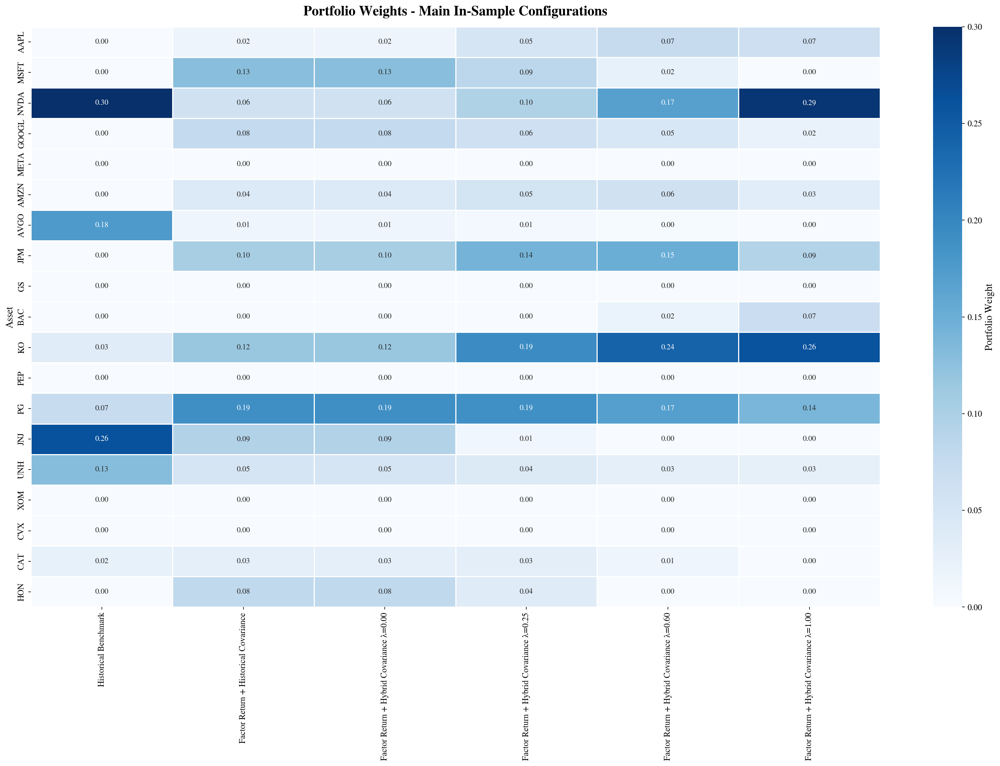

In [47]:
fig = plot_global_weights_heatmap(global_weights)
plt.show()

# Part 8: Rolling backtest on the factorial model

This section tests, out-of-sample, the central methodological choice of Parts 1-2: does the
FF6 factor-based estimate of $\mu$ improve risk-adjusted performance relative to the historical
mean, when both share the **same historical covariance**? Isolating $\mu$ this way keeps the test
focused on the return model alone — historical vs implied/hybrid covariance is the separate
question studied in Parts 3-5.

Methodology:
- Rolling estimation window: 36 months
- Rebalancing: monthly — $\mu$, $\Sigma$ and the risk-free rate are all re-estimated on each new
  window, so a rebalancing date never uses information from its own future
- Constraints: long-only, 30%-per-asset cap (same `bounds` as the rest of the analysis)
- External reference: S&P 500 (`spy_returns`, already computed in Part 1)

Both configurations reuse the same building blocks as the rest of the notebook
(`compute_naive_expected_returns`, `build_ff6_regression_table`, `compute_factor_expected_returns`,
`compute_historical_covariance`, `optimize_max_sharpe`), composed inside `rolling_backtest`
(`backtest.py`) rather than duplicated locally.

In [48]:
bt_returns, bt_weights = rolling_backtest(
    data=data,
    tickers=TICKERS,
    lookback=36,
    bounds=bounds
)

rf_bt = data["RF"].reindex(bt_returns.index)
risk_free_rate_bt = (1 + rf_bt.mean()) ** FREQUENCY - 1

bt_returns.head()

,Historical Benchmark,Factor-Based (FF6)
Date,,
2018-02,-0.039959,-0.042103
2018-03,-0.064032,-0.046913
2018-04,0.024135,0.015617
2018-05,0.076127,0.024317
2018-06,-0.005231,0.008014


## Cumulative performance vs SPY

Cumulative growth of \$1 invested in each rolling configuration against the S&P 500 over the
same out-of-sample period (the first 36 months of `data` have no backtest observation, since
they are needed to estimate the first rolling window).

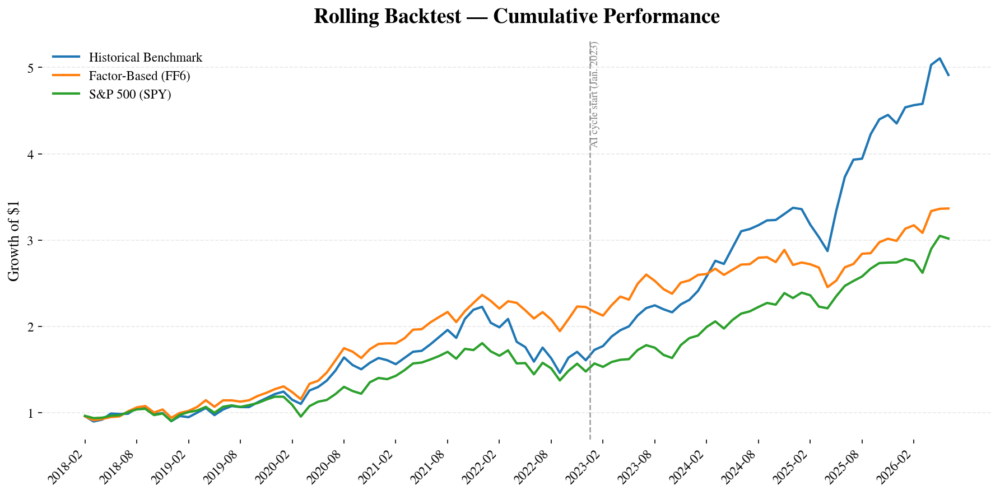

In [49]:
spy_bt_returns = spy_returns.reindex(bt_returns.index)

cum_perf = (1 + bt_returns).cumprod()
cum_perf["S&P 500 (SPY)"] = (1 + spy_bt_returns).cumprod()

fig = plot_backtest_cumulative_performance(cum_perf)
fig.savefig("figures/backtest_cumulative_performance.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Backtest performance statistics

Annualized return, volatility, Sharpe ratio and maximum drawdown computed directly from the
realized (ex-post) return series above. The Sharpe and Sortino ratios net each period's return
against that same period's Fama-French risk-free rate (`rf_bt`) before annualizing, rather than
subtracting a single period-averaged rate from an already-annualized return - the more precise
convention when the risk-free rate moves materially within the window being evaluated, as it
does here (2018-2026 spans both near-zero rates and the 2022 hiking cycle). `risk_free_rate_bt`
(the annualized average of `rf_bt` over this same window) is kept only as a descriptive
reference figure below, not as an input to these ratios; it is not the full-sample scalar used
in Parts 1-5 either way. The rolling, window-averaged risk-free rate inside `rolling_backtest` is
a separate concern: it only drives the optimizer at each rebalancing date, using information
available at that time.


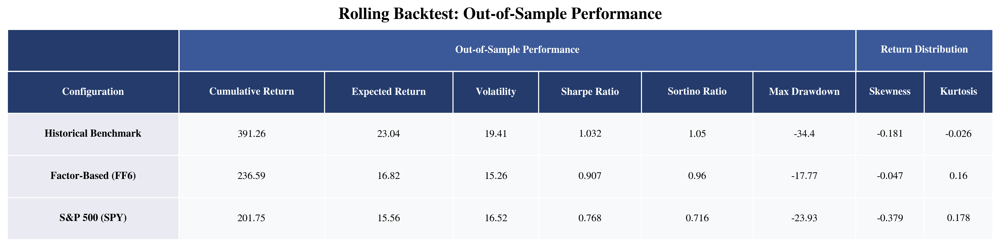

In [50]:
backtest_series = {
    "Historical Benchmark": bt_returns["Historical Benchmark"],
    "Factor-Based (FF6)": bt_returns["Factor-Based (FF6)"],
    "S&P 500 (SPY)": spy_bt_returns
}

backtest_stats = {}
for label, series in backtest_series.items():
    ann_return, ann_vol, sharpe = annualized_stats(series, rf_bt)
    backtest_stats[label] = {
        "Cumulative Return": cumulative_return(series) * 100,
        "Expected Return": ann_return * 100,
        "Volatility": ann_vol * 100,
        "Sharpe Ratio": sharpe,
        "Sortino Ratio": sortino_ratio(series, rf_bt),
        "Max Drawdown": max_drawdown(series) * 100,
        "Skewness": series.skew(),
        "Kurtosis": series.kurtosis()
    }

backtest_stats = pd.DataFrame(backtest_stats).T
backtest_stats_formatted = format_portfolio_metrics(backtest_stats)

fig = plot_combined_metrics_table(
    backtest_stats_formatted,
    table_groups={
        "Out-of-Sample Performance": ["Cumulative Return", "Expected Return", "Volatility", "Sharpe Ratio", "Sortino Ratio", "Max Drawdown"],
        "Return Distribution": ["Skewness", "Kurtosis"]
    },
    title="Rolling Backtest: Out-of-Sample Performance",
    index_label="Configuration"
)

fig.savefig("figures/backtest_performance_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Rolling Sharpe ratio (12-month window)

A single Sharpe ratio over the whole backtest period (table above) hides how risk-adjusted
performance evolves over time. We compute a 12-month rolling Sharpe for each configuration,
netting each window's returns against `rf_bt` period by period (same convention as the stats
table above) - to see whether one configuration is consistently better, or only wins during
specific sub-periods.


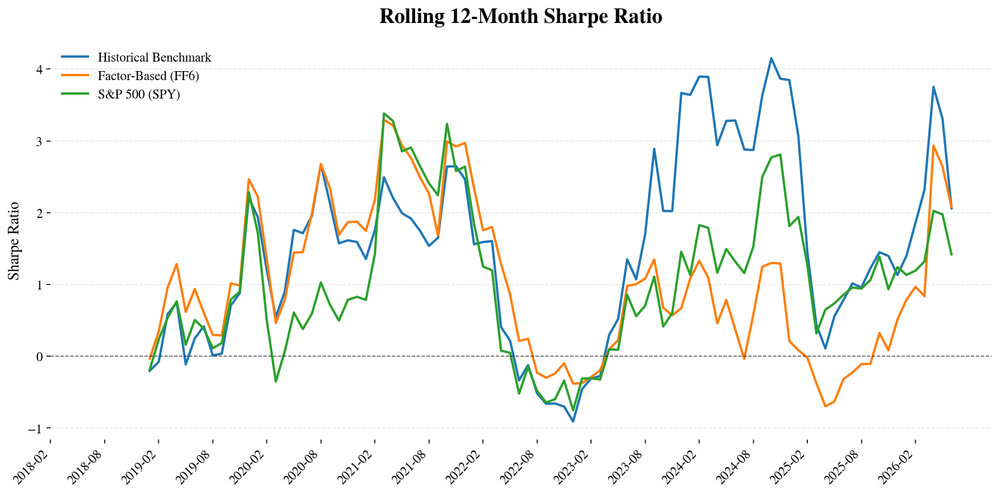

In [51]:
rolling_sharpe = pd.DataFrame({
    label: rolling_sharpe_ratio(series, rf_bt, window=12)
    for label, series in backtest_series.items()
})

fig = plot_backtest_rolling_sharpe(rolling_sharpe)
fig.savefig("figures/backtest_rolling_sharpe.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Portfolio weight evolution

Monthly weight allocation for each backtest configuration (S&P 500 has no internal weights to
show, since it is a single passive position). Each stacked area sums to 100% at every date,
since both configurations are long-only and fully invested.

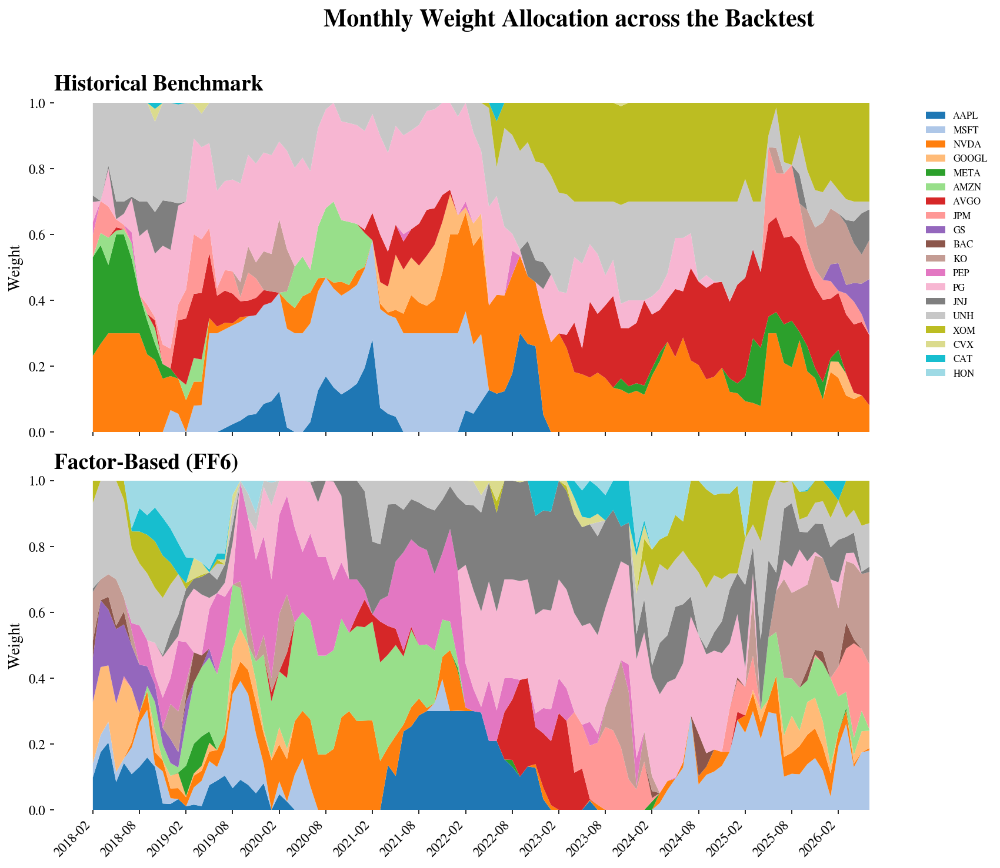

In [52]:
fig = plot_backtest_weights_stacked(bt_weights, TICKERS)
fig.savefig("figures/backtest_weights_stacked.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Underwater plot (drawdown)

Drawdown at each date $t$ relative to the running maximum of the cumulative wealth curve:

$$ drawdown(t) = \frac{cumulative(t) - \max(cumulative[:t])}{\max(cumulative[:t])} $$

Plotted for all three configurations together, with the area below zero filled in a
semi-transparent version of each line's color, consistent with the rest of the backtest charts.

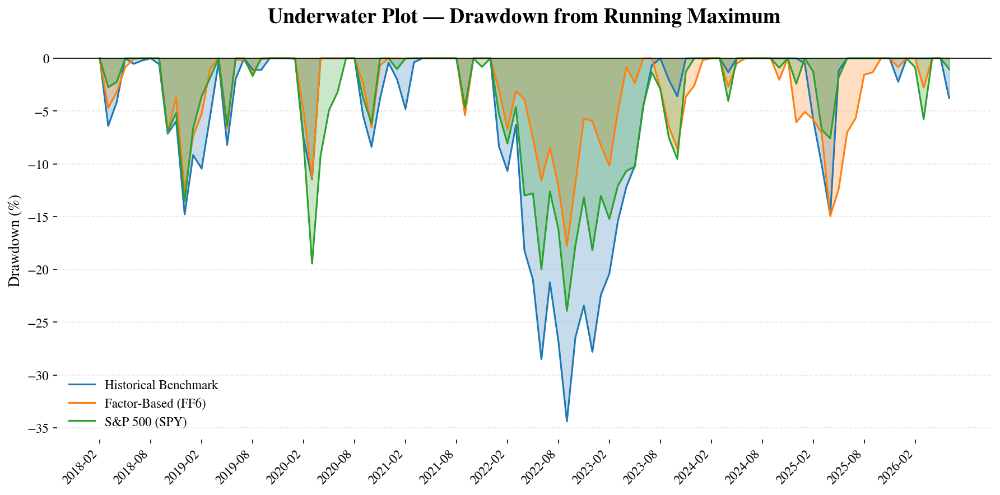

In [53]:
drawdowns = pd.DataFrame({
    label: drawdown_series(series) * 100
    for label, series in backtest_series.items()
})

fig = plot_underwater(drawdowns)
fig.savefig("figures/backtest_underwater_plot.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Statistical significance: Ledoit & Wolf (2008) test

We test $H_0: SR_{Historical} = SR_{FF6}$ using the studentized stationary bootstrap of
Ledoit & Wolf (2008), resampling the return series and the risk-free rate along the **same**
bootstrap path (Politis & Romano, 1994) at each replication, to preserve their cross-correlation
and keep each return paired with its own period's rate.

The Sharpe ratio used here follows the compounded annualization convention of `annualized_stats`
above (`sharpe_ratio_compounded`), not the linear convention of Ledoit & Wolf's original paper -
see Annexe \\ref{bootstrap} of the write-up for the delta-method argument justifying this
substitution. Both this test and the descriptive table above net returns against `rf_bt` period
by period, so the two Sharpe numbers now coincide exactly by construction - see the consistency
check below.


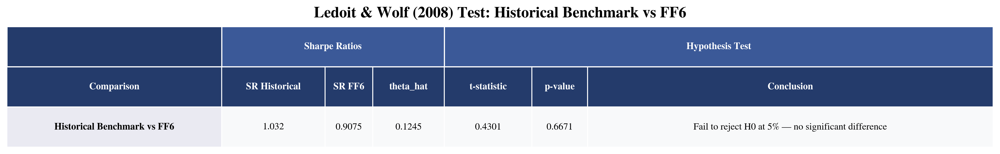

In [54]:
lw_result = ledoit_wolf_test(
    r_bench=bt_returns["Historical Benchmark"].values,
    r_ff6=bt_returns["Factor-Based (FF6)"].values,
    rf=rf_bt.values,
    n_bootstrap=5000,
    frequency=FREQUENCY,
    seed=42
)

alpha = 0.05
conclusion = (
    "Reject H0 at 5% — Sharpe ratios are significantly different"
    if lw_result["p_value"] < alpha
    else "Fail to reject H0 at 5% — no significant difference"
)

lw_table = pd.DataFrame({
    "Historical Benchmark vs FF6": {
        "SR Historical": round(lw_result["SR_bench"], 4),
        "SR FF6": round(lw_result["SR_ff6"], 4),
        "theta_hat": round(lw_result["theta_hat"], 4),
        "t-statistic": round(lw_result["t_stat"], 4),
        "p-value": round(lw_result["p_value"], 4),
        "Conclusion": conclusion
    }
}).T

fig = plot_combined_metrics_table(
    lw_table,
    table_groups={
        "Sharpe Ratios": ["SR Historical", "SR FF6", "theta_hat"],
        "Hypothesis Test": ["t-statistic", "p-value", "Conclusion"]
    },
    title="Ledoit & Wolf (2008) Test: Historical Benchmark vs FF6",
    index_label="Comparison"
)

fig.savefig("figures/ledoit_wolf_test.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Consistency check: Sharpe ratio sources

The main backtest table and the Ledoit-Wolf test now evaluate the same out-of-sample period and
net returns against the same period-by-period risk-free rate (`rf_bt`). The only remaining,
deliberate difference between the two Sharpe ratios was the annualization formula - both are now
compounded, so this check mainly documents that the switch away from the legacy linear
definition (`sharpe_ratio`) is complete. `risk_free_rate_bt` and the full-sample `risk_free_rate`
(used elsewhere in the notebook, e.g. Parts 1-5) are shown below only as descriptive reference
figures, not as inputs to either Sharpe ratio.

**History, for context:**
- *2026-08-01* - this cell originally documented a real gap between the main backtest table's
  Sharpe ratio (compounded annualization, via `annualized_stats`) and the Ledoit-Wolf test's
  Sharpe ratio (linear annualization, Ledoit & Wolf's own exact definition). `ledoit_wolf_test`
  has since been switched to `sharpe_ratio_compounded` (see `statistical_tests.py`), so
  `SR_bench`/`SR_ff6` now match the main table exactly by construction - see the delta-method
  argument in Annexe (bootstrap) of the write-up for why this substitution preserves the test's
  asymptotic validity. The legacy linear column below is kept purely as a historical record of
  that original gap.
- *2026-08-13* - `annualized_stats`/`rolling_sharpe_ratio`/`sortino_ratio`/`sharpe_ratio_compounded`
  were further updated to accept a period-by-period risk-free rate (`rf_bt`) instead of a single
  averaged scalar, netting returns against `rf` month by month before annualizing (see
  `portfolio_metrics.py` and `statistical_tests.py`). Everything below now uses `rf_bt` directly,
  so it stays consistent by construction.

In [55]:
print(f"Risk-free rate, full sample (2015-2026, used in Parts 1-5): {risk_free_rate:.4%}")
print(f"Risk-free rate, backtest period only ({bt_returns.index[0]} to {bt_returns.index[-1]}, used throughout Part 6): {risk_free_rate_bt:.4%}")

sharpe_method_params = pd.DataFrame({
    "Main backtest table (annualized_stats)": {
        "Annualization formula": "(1 + mean)^12 - 1  [compounded]",
    },
    "Ledoit-Wolf test, as used now (sharpe_ratio_compounded)": {
        "Annualization formula": "(1 + mean)^12 - 1  [compounded]",
    },
    "Ledoit-Wolf test, original definition (sharpe_ratio, no longer used)": {
        "Annualization formula": "mean / std * sqrt(12)  [linear]",
    },
})
display(sharpe_method_params)

sharpe_check_rows = []
for label in ["Historical Benchmark", "Factor-Based (FF6)"]:
    series = bt_returns[label]
    e = series.values - rf_bt.values

    sharpe_compounded = sharpe_ratio_compounded(series.values, rf_bt.values, frequency=FREQUENCY)
    sharpe_linear_legacy = sharpe_ratio(e, frequency=FREQUENCY)

    sharpe_check_rows.append({
        "Configuration": label,
        "Sharpe (compounded, used everywhere incl. LW test)": round(sharpe_compounded, 4),
        "Sharpe (linear, legacy / no longer used)": round(sharpe_linear_legacy, 4),
    })

sharpe_consistency_check = pd.DataFrame(sharpe_check_rows).set_index("Configuration")
print("\nThe Ledoit-Wolf test now reports the compounded Sharpe ratio everywhere - identical to")
print("the main backtest table by construction. The legacy linear column is shown only to")
print("document what the test used to report before this change.")
sharpe_consistency_check

Risk-free rate, full sample (2015-2026, used in Parts 1-5): 2.0039%
Risk-free rate, backtest period only (2018-02 to 2026-06, used throughout Part 6): 2.5907%


,Main backtest table (annualized_stats),"Ledoit-Wolf test, as used now (sharpe_ratio_compounded)","Ledoit-Wolf test, original definition (sharpe_ratio, no longer used)"
Annualization formula,(1 + mean)^12 - 1 [compounded],(1 + mean)^12 - 1 [compounded],mean / std * sqrt(12) [linear]



The Ledoit-Wolf test now reports the compounded Sharpe ratio everywhere - identical to
the main backtest table by construction. The legacy linear column is shown only to
document what the test used to report before this change.


,"Sharpe (compounded, used everywhere incl. LW test)","Sharpe (linear, legacy / no longer used)"
Configuration,,
Historical Benchmark,1.0320,0.9528
Factor-Based (FF6),0.9075,0.8586


## Bootstrap distribution and confidence intervals

Two complementary views of the same 1000 bootstrap replications: the distribution of the
Sharpe-ratio difference itself (left), and the individual Sharpe ratios with their own
bootstrap confidence intervals computed separately from each series' bootstrap draws (right).

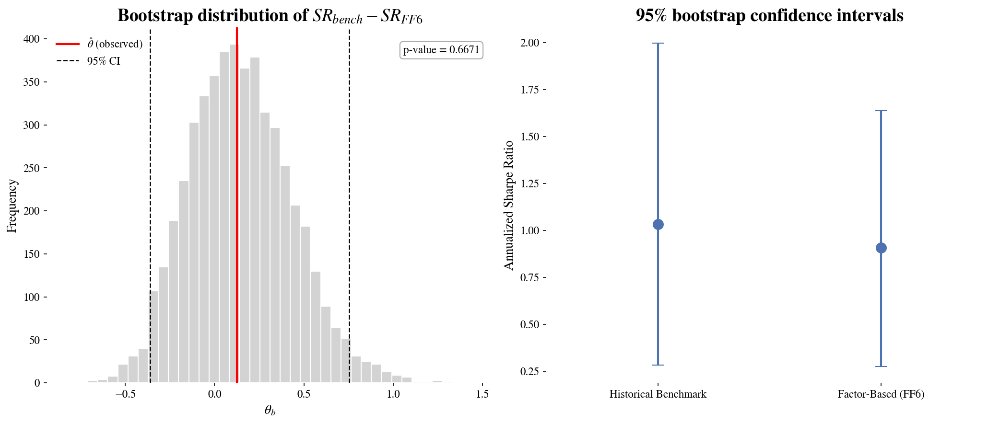

In [56]:
fig = plot_ledoit_wolf_bootstrap(lw_result)
fig.savefig("figures/ledoit_wolf_bootstrap_charts.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Sortino ratio: statistical significance (robustness check)

Same studentized stationary bootstrap as above, but comparing the Sortino ratio instead of the
Sharpe ratio (`ledoit_wolf_test(..., ratio_fn=sortino_ratio)`) - a check on whether the "no
significant difference" conclusion holds regardless of which risk-adjusted metric is used, not
just for the Sharpe ratio specifically.

Note: the delta-method proof of asymptotic validity in Annexe \ref{bootstrap} is written for the
compounded Sharpe ratio; it does not itself cover the Sortino ratio, whose downside-deviation
denominator is not the same smooth function of the return moments. This result should therefore
be read as an informal robustness check, not as carrying the same asymptotic guarantee as the
Sharpe-based test above.

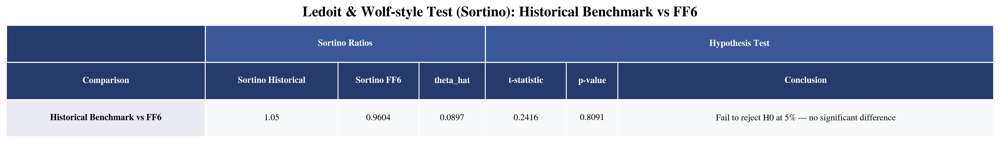

In [57]:
lw_result_sortino = ledoit_wolf_test(
    r_bench=bt_returns["Historical Benchmark"].values,
    r_ff6=bt_returns["Factor-Based (FF6)"].values,
    rf=rf_bt.values,
    n_bootstrap=5000,
    frequency=FREQUENCY,
    seed=42,
    ratio_fn=sortino_ratio
)

conclusion_sortino = (
    "Reject H0 at 5% — Sortino ratios are significantly different"
    if lw_result_sortino["p_value"] < alpha
    else "Fail to reject H0 at 5% — no significant difference"
)

lw_table_sortino = pd.DataFrame({
    "Historical Benchmark vs FF6": {
        "Sortino Historical": round(lw_result_sortino["SR_bench"], 4),
        "Sortino FF6": round(lw_result_sortino["SR_ff6"], 4),
        "theta_hat": round(lw_result_sortino["theta_hat"], 4),
        "t-statistic": round(lw_result_sortino["t_stat"], 4),
        "p-value": round(lw_result_sortino["p_value"], 4),
        "Conclusion": conclusion_sortino
    }
}).T

fig = plot_combined_metrics_table(
    lw_table_sortino,
    table_groups={
        "Sortino Ratios": ["Sortino Historical", "Sortino FF6", "theta_hat"],
        "Hypothesis Test": ["t-statistic", "p-value", "Conclusion"]
    },
    title="Ledoit & Wolf-style Test (Sortino): Historical Benchmark vs FF6",
    index_label="Comparison"
)

fig.savefig("figures/ledoit_wolf_test_sortino.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Sub-period breakdown: isolating the AI cycle

The full out-of-sample period (Feb. 2018 - Jun. 2026, see the vertical marker above) spans two
fairly different regimes: a calmer 2018-2022 period and the 2023-2026 AI-driven bull market. We
split the backtest into these two sub-periods and recompute the same performance metrics for
each, using the **sub-period average** risk-free rate (not the full-sample one) for each Sharpe
ratio, since rates moved substantially between the two windows.

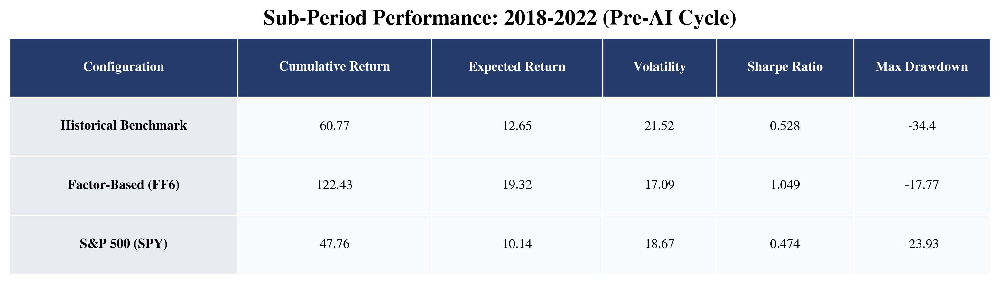

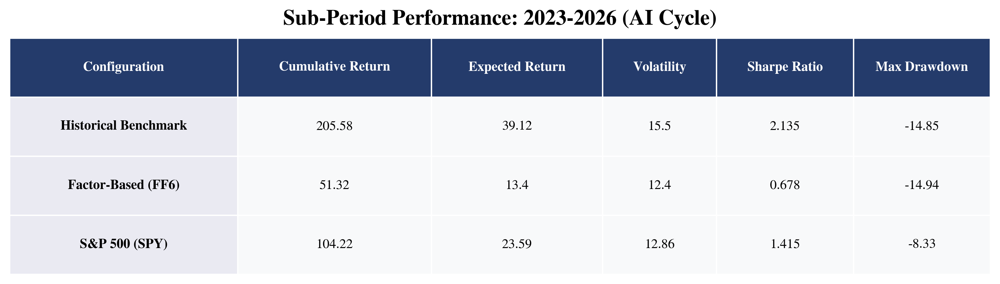

In [58]:
SUBPERIODS = {
    "2018-2022 (Pre-AI Cycle)": ("2018-01", "2022-12"),
    "2023-2026 (AI Cycle)": ("2023-01", "2026-06")
}

for label, (start, end) in SUBPERIODS.items():
    period_stats = {}
    for series_label, series in backtest_series.items():
        sub_series = series.loc[start:end]
        rf_sub_series = rf_bt.loc[start:end]
        ann_return, ann_vol, sharpe = annualized_stats(sub_series, rf_sub_series)
        period_stats[series_label] = {
            "Cumulative Return": cumulative_return(sub_series) * 100,
            "Expected Return": ann_return * 100,
            "Volatility": ann_vol * 100,
            "Sharpe Ratio": sharpe,
            "Max Drawdown": max_drawdown(sub_series) * 100
        }

    period_table = pd.DataFrame(period_stats).T
    period_table_formatted = format_portfolio_metrics(period_table)

    fig = plot_combined_metrics_table(
        period_table_formatted,
        table_groups={"Performance": ["Cumulative Return", "Expected Return", "Volatility", "Sharpe Ratio", "Max Drawdown"]},
        title=f"Sub-Period Performance: {label}",
        index_label="Configuration"
    )

    fig.savefig(f"backtest_subperiod_{label.split()[0]}.png", dpi=300, bbox_inches="tight")
    if SHOW_FIGURES:
        plt.show()
    else:
        plt.close(fig)

# Part 9: Stress tests on implied volatilities

## Scenario definitions

The lambda-grid analysis in Part 4 relies on a single implied volatility snapshot, captured
at one point in time. This section tests how sensitive the resulting allocations and metrics
are to that snapshot, by applying controlled shocks to `implied_vols_filled` and re-running
the exact same hybrid-covariance / max-Sharpe pipeline across the full lambda grid for each
shocked scenario - holding returns, factor expected returns and the correlation structure
fixed throughout. The unshocked case is not recomputed here: it is exactly `lambda_metrics`
from Part 4, reused below as the baseline.

In [59]:
SCENARIOS = {
    "Uniform IV Increase (+20%)": dict(shock_type="uniform", multiplier=1.20),
    "Uniform IV Decrease (-20%)": dict(shock_type="uniform", multiplier=0.80),
    "Tech Sector Shock (+30%)": dict(
        shock_type="subset", multiplier=1.30,
        shock_tickers=["AAPL", "MSFT", "NVDA", "GOOGL", "META", "AVGO"]
    ),
    "Defensive Sector Shock (+20%)": dict(
        shock_type="subset", multiplier=1.20,
        shock_tickers=["KO", "PEP", "PG", "JNJ", "UNH"]
    ),
    "Historical Crisis Shock (VIX x4)": dict(shock_type="uniform", multiplier=4.0),
    "Hierarchy Inversion": dict(shock_type="invert"),
}

## Running all scenarios across the lambda grid

In [60]:
stress_results = {
    label: run_stress_scenario(
        returns=data[TICKERS],
        tickers=TICKERS,
        mu=mu_factor,
        implied_vols=implied_vols_filled,
        lambda_grid=lambda_grid,
        risk_free_rate=risk_free_rate,
        bounds=bounds,
        **params
    )
    for label, params in SCENARIOS.items()
}

# Baseline (unshocked) is already available from Part 4 - reused, not recomputed.
stress_results["Baseline (Current IV)"] = lambda_metrics

## Sharpe ratio across the lambda grid, baseline vs each scenario

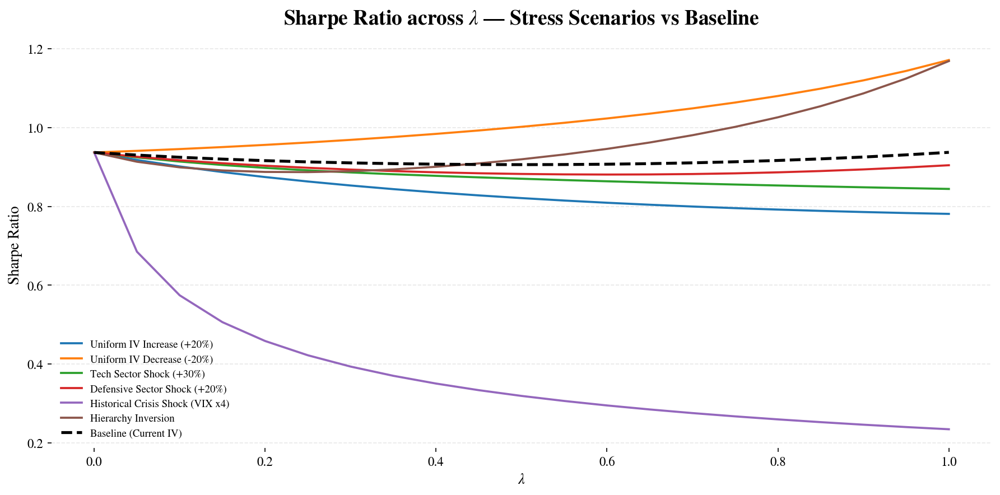

In [61]:
fig = plot_stress_sharpe_across_lambda(stress_results)
fig.savefig("figures/stress_test_sharpe_across_lambda.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Summary at the reference configuration ($\lambda = 0.25$)

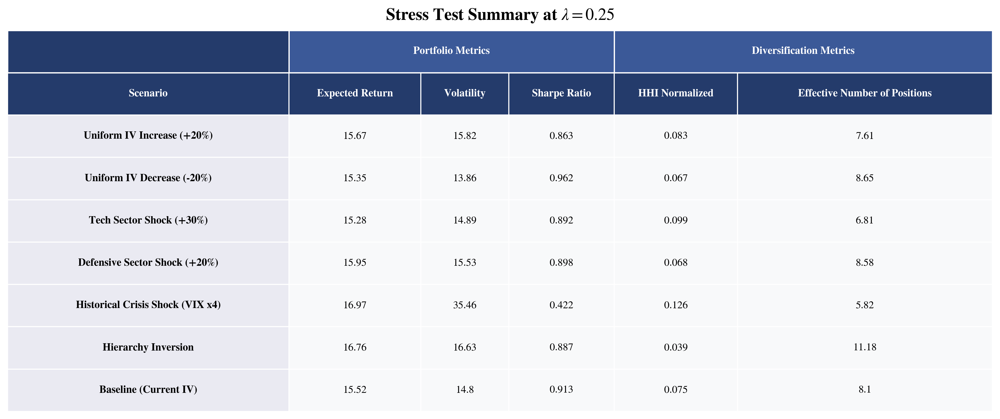

In [62]:
stress_summary_025 = pd.DataFrame({
    label: df.loc[0.25]
    for label, df in stress_results.items()
}).T

stress_summary_025_formatted = format_portfolio_metrics(stress_summary_025)

fig = plot_combined_metrics_table(
    stress_summary_025_formatted,
    table_groups={
        "Portfolio Metrics": ["Expected Return", "Volatility", "Sharpe Ratio"],
        "Diversification Metrics": ["HHI Normalized", "Effective Number of Positions"]
    },
    title=r"Stress Test Summary at $\lambda = 0.25$",
    index_label="Scenario"
)

fig.savefig("figures/stress_test_summary_lambda025.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Diagnostic: understanding the "Hierarchy Inversion" scenario

This scenario reaches a Sharpe ratio at $\lambda = 0.25$ nearly identical to the baseline, yet
its diversification metrics (HHI, ENP) are markedly better. Before writing this up, we inspect
the actual weight allocation behind it, compared ticker by ticker to the baseline weights
already computed in Part 4 (`lambda_weights["0.25"]`), alongside the original and inverted IV
values, to understand the mechanism rather than just observe the aggregate metrics.

In [63]:
w_baseline_025 = lambda_weights["0.25"]
w_inverted_025 = get_stress_scenario_weights(
    returns=data[TICKERS],
    tickers=TICKERS,
    mu=mu_factor,
    implied_vols=implied_vols_filled,
    lambda_=0.25,
    risk_free_rate=risk_free_rate,
    bounds=bounds,
    shock_type="invert"
)

iv_inverted = apply_iv_shock(implied_vols_filled, shock_type="invert")

diagnostic_table = pd.DataFrame({
    "IV originale (%)": implied_vols_filled * 100,
    "IV inversée (%)": iv_inverted * 100,
    "Poids baseline (%)": w_baseline_025 * 100,
    "Poids inversion (%)": w_inverted_025 * 100,
}).round(2)
diagnostic_table["Δ poids (pts)"] = (diagnostic_table["Poids inversion (%)"] - diagnostic_table["Poids baseline (%)"]).round(2)
diagnostic_table = diagnostic_table.sort_values("IV originale (%)", ascending=False)

diagnostic_table

,IV originale (%),IV inversée (%),Poids baseline (%),Poids inversion (%),Δ poids (pts)
META,38.66,18.13,0.00,4.91,4.91
AVGO,36.41,20.63,0.63,6.65,6.02
CAT,36.29,24.78,3.10,9.08,5.98
GS,36.20,26.11,0.00,10.33,10.33
UNH,34.95,26.54,4.05,10.80,6.75
NVDA,33.66,27.05,9.53,10.98,1.45
AMZN,32.65,27.22,5.41,7.14,1.73
XOM,31.97,27.36,0.00,2.48,2.48
GOOGL,30.21,28.23,6.29,7.27,0.98
CVX,28.36,28.36,0.00,0.00,0.00


In [64]:
print("Number of active positions (>0.5%):")
print(f"  Baseline (λ=0.25): {(w_baseline_025 > 0.005).sum()}")
print(f"  Inversion (λ=0.25): {(w_inverted_025 > 0.005).sum()}")
print()
print(f"Maximum weight: baseline {w_baseline_025.max():.2%} ({w_baseline_025.idxmax()}) vs "
      f"inversion {w_inverted_025.max():.2%} ({w_inverted_025.idxmax()})")

Number of active positions (>0.5%):
  Baseline (λ=0.25): 13
  Inversion (λ=0.25): 13

Maximum weight: baseline 19.34% (KO) vs inversion 14.18% (PG)


## Visualizing the reallocation: baseline vs inverted composition

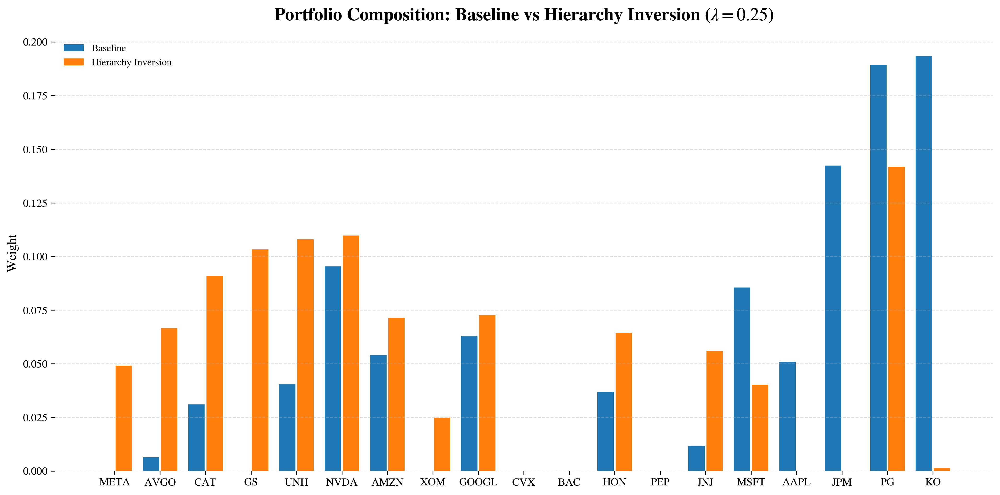

In [65]:
weights_comparison_inversion = pd.DataFrame({
    "Baseline": w_baseline_025,
    "Hierarchy Inversion": w_inverted_025
}).reindex(implied_vols_filled.sort_values(ascending=False).index)

fig, ax = plot_weight_comparison(weights_comparison_inversion, figsize=(14, 7))
ax.set_title(
    "Portfolio Composition: Baseline vs Hierarchy Inversion ($\\lambda=0.25$)",
    fontsize=18, weight="bold", pad=15
)
ax.set_ylabel("Weight")

plt.savefig("figures/stress_test_inversion_weights.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## How much, and how concentratedly, does each scenario reallocate the portfolio?

At the reference $\lambda = 0.25$, we compare each scenario's optimized weights to the
baseline weights (`lambda_weights["0.25"]`), using `weight_shift_metrics`: the turnover
between the two allocations (fraction of the portfolio that would need to be traded), and
the effective number of positions absorbing that reallocation (1 = concentrated on a single
asset, up to $n$ = spread evenly across the whole universe).

In [66]:
shift_rows = {}
for label, params in SCENARIOS.items():
    w_scenario_025 = get_stress_scenario_weights(
        returns=data[TICKERS],
        tickers=TICKERS,
        mu=mu_factor,
        implied_vols=implied_vols_filled,
        lambda_=0.25,
        risk_free_rate=risk_free_rate,
        bounds=bounds,
        **params
    )
    shift_rows[label] = weight_shift_metrics(w_baseline_025, w_scenario_025)

scenario_shift_table = pd.DataFrame(shift_rows).T

# Turnover displayed as a percentage (matches the "Expected Return"/"Volatility"
# convention elsewhere); ENP (Shift) is a position count, left as-is.
scenario_shift_table["Turnover"] = (scenario_shift_table["Turnover"] * 100).round(1).map(lambda v: f"{v:.1f}%")
scenario_shift_table["Effective Number of Positions (Shift)"] = scenario_shift_table["Effective Number of Positions (Shift)"].round(3)

# Baseline-vs-itself reference row: turnover is trivially zero by construction,
# and the shift-concentration metric is undefined (no shift to distribute over).
scenario_shift_table.loc["Baseline (Current IV)"] = ["0.0%", "\u2014"]
scenario_shift_table = scenario_shift_table.reindex(
    ["Baseline (Current IV)"] + list(SCENARIOS.keys())
)
scenario_shift_table

,Turnover,Effective Number of Positions (Shift)
Baseline (Current IV),0.0%,—
Uniform IV Increase (+20%),4.8%,8.835
Uniform IV Decrease (-20%),5.5%,8.263
Tech Sector Shock (+30%),13.8%,6.897
Defensive Sector Shock (+20%),7.4%,9.59
Historical Crisis Shock (VIX x4),27.3%,7.634
Hierarchy Inversion,47.8%,9.845


## Exporting the scenario shift table as a figure

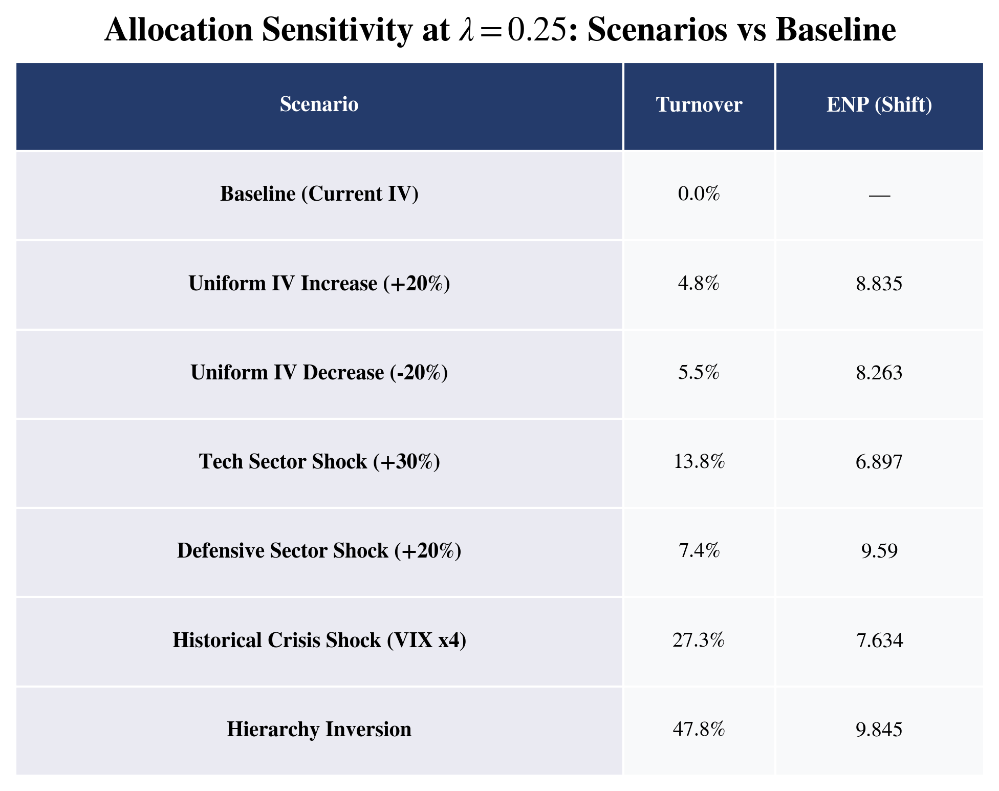

In [67]:
scenario_shift_formatted = format_portfolio_metrics(scenario_shift_table)

fig = plot_combined_metrics_table(
    scenario_shift_formatted,
    table_groups={"Allocation Sensitivity": ["Turnover", "Effective Number of Positions (Shift)"]},
    column_labels={"Effective Number of Positions (Shift)": "ENP (Shift)"},
    title=r"Allocation Sensitivity at $\lambda = 0.25$: Scenarios vs Baseline",
    index_label="Scenario"
)

fig.savefig("figures/stress_test_scenario_shift.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

# Part 10: Stability analysis

This section completes the robustness evaluation of Part 6-7 with three metrics tied directly
to hypothesis H4. H4's third component (adaptation to market regime changes) was already tested
via the sub-period breakdown above (Part 6); this section covers the two remaining components -
temporal stability of the allocations (turnover) and concentration (HHI / effective number of
positions) - plus a check on the stability of the FF6 model's own factor readings over time.

## Turnover across the backtest

Month-over-month turnover (one-way L1 distance between consecutive months' weights, via
`weight_shift_metrics`) for each backtest configuration, over the same out-of-sample period as
Part 6.

In [68]:
turnover_series = {}
for label, weights_df in bt_weights.items():
    turnovers = [
        weight_shift_metrics(weights_df.iloc[i - 1], weights_df.iloc[i])["Turnover"]
        for i in range(1, len(weights_df))
    ]
    turnover_series[label] = pd.Series(turnovers, index=weights_df.index[1:])

turnover_df = pd.DataFrame(turnover_series)
turnover_df.head()

,Historical Benchmark,Factor-Based (FF6)
2018-03,0.120041,0.214969
2018-04,0.202908,0.084087
2018-05,0.256020,0.181506
2018-06,0.038617,0.186848
2018-07,0.133263,0.261834


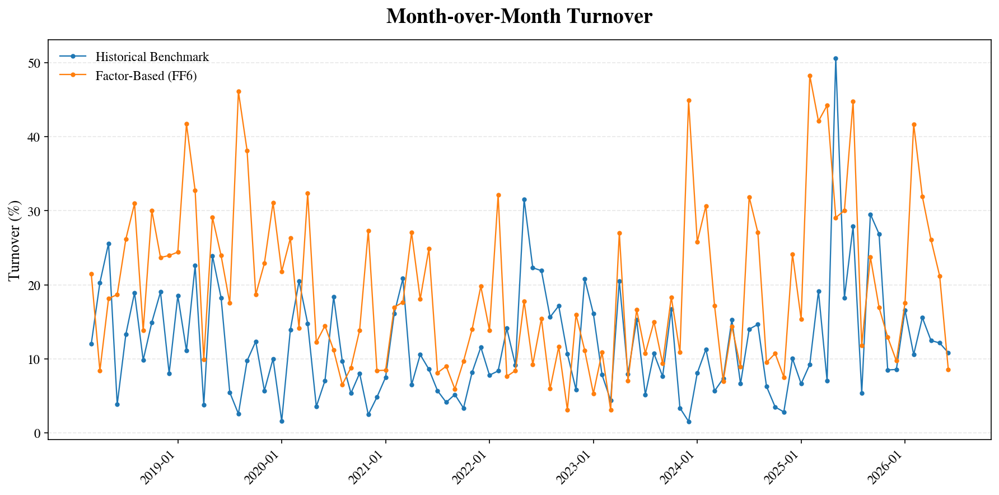

In [69]:
fig = plot_backtest_turnover(turnover_df)
fig.savefig("figures/backtest_turnover_series.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

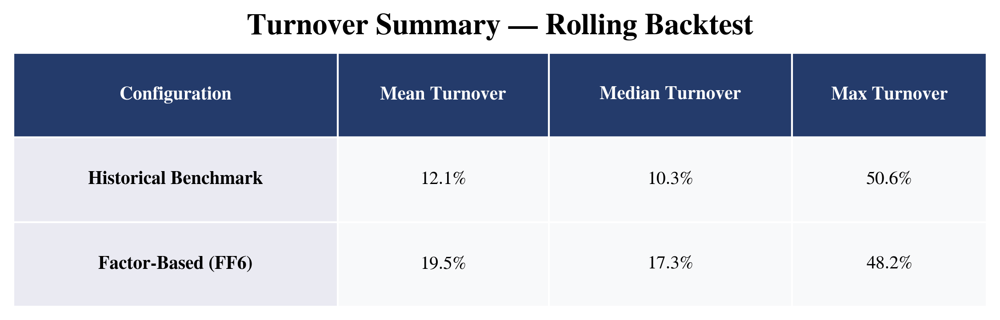

In [70]:
turnover_summary = pd.DataFrame({
    "Mean Turnover": turnover_df.mean(),
    "Median Turnover": turnover_df.median(),
    "Max Turnover": turnover_df.max()
}) * 100

for col in turnover_summary.columns:
    turnover_summary[col] = turnover_summary[col].round(1).map(lambda v: f"{v:.1f}%")

fig = plot_combined_metrics_table(
    turnover_summary,
    table_groups={"Turnover": list(turnover_summary.columns)},
    title="Turnover Summary — Rolling Backtest",
    index_label="Configuration"
)

fig.savefig("figures/backtest_turnover_summary.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## HHI and effective number of positions over time

Concentration of each backtest configuration at every rebalancing date, via
`hhi_normalized` and `effective_number_of_positions` applied to that date's realized weights -
complementing the point-in-time HHI/ENP readings already used in Part 4-5 with their evolution
over the out-of-sample period.

In [71]:
hhi_over_time = {}
enp_over_time = {}

for label, weights_df in bt_weights.items():
    hhi_over_time[label] = weights_df.apply(lambda w: hhi_normalized(w.values), axis=1)
    enp_over_time[label] = weights_df.apply(lambda w: effective_number_of_positions(w.values), axis=1)

hhi_over_time_df = pd.DataFrame(hhi_over_time)
enp_over_time_df = pd.DataFrame(enp_over_time)

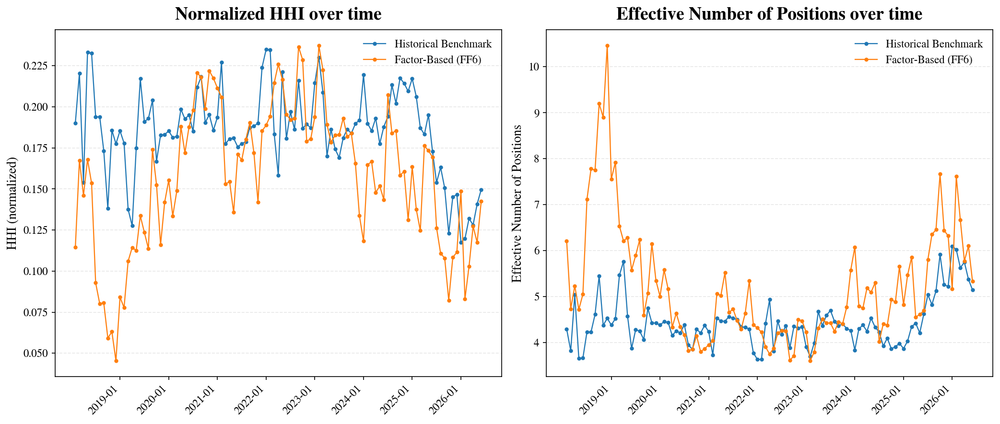

In [72]:
fig = plot_backtest_concentration(hhi_over_time_df, enp_over_time_df)
fig.savefig("figures/backtest_hhi_enp_series.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

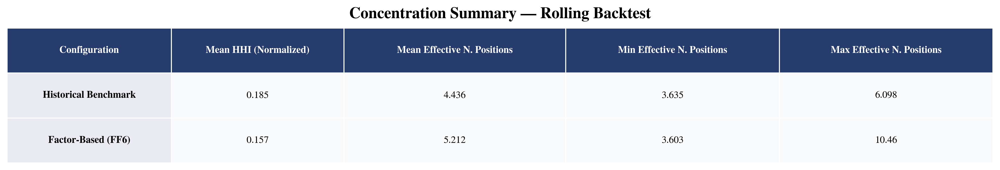

In [73]:
concentration_summary = pd.DataFrame({
    "Mean HHI (Normalized)": hhi_over_time_df.mean(),
    "Mean Effective N. Positions": enp_over_time_df.mean(),
    "Min Effective N. Positions": enp_over_time_df.min(),
    "Max Effective N. Positions": enp_over_time_df.max()
}).round(3)

fig = plot_combined_metrics_table(
    concentration_summary,
    table_groups={"Concentration": list(concentration_summary.columns)},
    title="Concentration Summary — Rolling Backtest",
    index_label="Configuration"
)

fig.savefig("figures/backtest_hhi_enp_summary.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Factor stability: rolling FF6 betas

Re-running the FF6 regression (Part 2) on the same rolling 36-month windows as the backtest,
sampled every 6 months to keep this light, to check whether the model's own factor readings for
the universe drift over time or stay consistent - a direct empirical answer to the question
raised at the start of this section: are the results driven by forward-looking information in
the covariance, or by the specific FF6 estimation window?

In [74]:
factor_stability_rows = []
for t in range(36, len(data), 1):
    window = data.iloc[t - 36:t]
    reg_table = build_ff6_regression_table(data=window, tickers=TICKERS)
    factor_stability_rows.append({
        "Date": data.index[t],
        "Avg Mkt-RF Beta": reg_table["Mkt-RF"].mean(),
        "Avg R2 (adj)": reg_table["R2_adj"].mean()
    })

factor_stability_df = pd.DataFrame(factor_stability_rows).set_index("Date")
factor_stability_df.head()

,Avg Mkt-RF Beta,Avg R2 (adj)
Date,,
2018-02,0.994349,0.444610
2018-03,1.021459,0.455329
2018-04,1.030586,0.450457
2018-05,1.027689,0.446745
2018-06,1.033194,0.454758


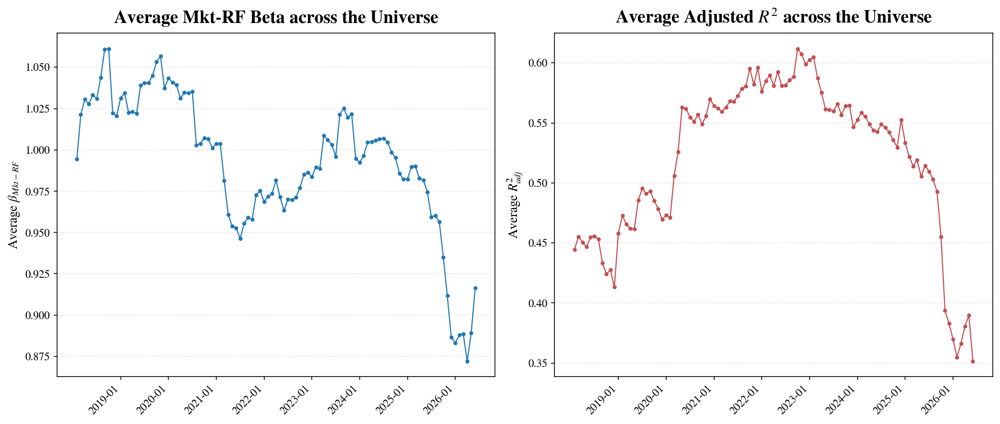

In [75]:
fig = plot_factor_stability(factor_stability_df)
fig.savefig("figures/ff6_beta_stability.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

# Part: Opening on ESG scores

In [76]:
from config import TICKERS, ESG_DATA_PATH, ESG_SHEET_NAME, ESG_SCORE_COLUMN
from esg_scores import load_lseg_esg_scores, build_esg_summary_for_display

esg_scores = load_lseg_esg_scores(
    path=ESG_DATA_PATH,
    tickers=TICKERS,
    score_column=ESG_SCORE_COLUMN,
    sheet_name=ESG_SHEET_NAME
)

esg_summary = build_esg_summary_for_display(
    path=ESG_DATA_PATH,
    tickers=TICKERS,
    sheet_name=ESG_SHEET_NAME
)

esg_summary.sort_values("ESG Score", ascending=False)


,Ticker,Company,ESG Score,Environmental,Social,Governance
Ticker,,,,,,
JNJ,JNJ,Johnson & Johnson,3.8,3.7,3.7,4.0
AAPL,AAPL,Apple Inc,3.4,3.5,2.3,4.5
AMZN,AMZN,Amazon Inc,3.3,2.9,3.3,3.8
MSFT,MSFT,Microsoft Corp,3.3,3.8,3.3,3.2
GS,GS,Goldman Sachs Group Inc,3.3,4.0,1.5,3.4
HON,HON,Honeywell International Inc,3.3,3.1,2.1,3.0
NVDA,NVDA,NVIDIA Corp,3.3,2.7,3.7,3.5
META,META,Meta Platforms Inc,3.2,3.3,3.5,3.1
PEP,PEP,PepsiCo Inc,3.1,2.9,2.9,3.6


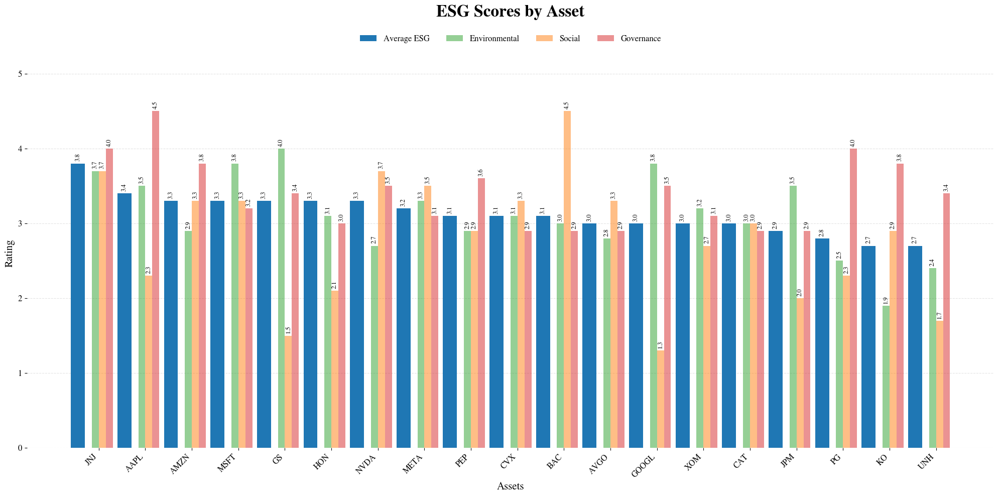

In [77]:
fig = plot_esg_scores_by_asset(esg_summary)
fig.savefig("figures/esg_scores_by_asset.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Constraining the portfolio by ESG score: the price of compliance

The scores above are purely descriptive. This section turns them into an actual constraint on
the optimizer — `make_min_esg_constraint` imposes $w^\top \text{ESG} \geqslant s_{ESG}$, a
**portfolio-weighted average** ESG score, not an asset-by-asset exclusion filter — and asks what
it costs, in risk-adjusted performance, to enforce it. Five thresholds are tested, from 3.0 to
3.4 in steps of 0.1 (LSEG's 0-5 scale).

A sixth, natural threshold — 3.5 — is deliberately left untested: under the long-only 30%-per-asset
cap already retained throughout this study, the maximum weighted-average ESG score any admissible
portfolio can reach is **3.48** (achieved by allocating the full 30% cap to each of the
highest-scoring assets in turn — JNJ, AAPL, AMZN — until the budget is exhausted). Past that point
the constraint set is empty, and the optimizer would simply have no feasible portfolio to return.
This is itself a small but genuine finding: the diversification cap imposed for risk-management
reasons mechanically bounds the ESG quality attainable, independently of the ESG constraint itself.

Two complementary views follow: a full out-of-sample rolling backtest, to measure the constraint's
cost over the whole study period, and a real-money translation of the final selected portfolio, to
make that cost concrete.

### Rolling backtest under the ESG constraint

In [78]:
esg_thresholds = [3.0, 3.1, 3.2, 3.3, 3.4]

esg_bt_returns, esg_bt_weights = rolling_backtest_esg(
    data=data,
    tickers=TICKERS,
    esg_scores=esg_scores,
    min_esg_scores=esg_thresholds,
    lookback=36,
    bounds=bounds
)

rf_esg_bt = data["RF"].reindex(esg_bt_returns.index)
esg_bt_returns.head()

,Factor-Based (FF6),ESG ≥ 3.0,ESG ≥ 3.1,ESG ≥ 3.2,ESG ≥ 3.3,ESG ≥ 3.4
Date,,,,,,
2018-02,-0.042103,-0.041459,-0.036993,-0.031761,-0.030255,-0.028897
2018-03,-0.046913,-0.046913,-0.048922,-0.045051,-0.041433,-0.038511
2018-04,0.015617,0.015617,0.013787,0.006458,-0.002630,-0.012938
2018-05,0.024317,0.024316,0.020960,0.015015,0.007239,-0.000176
2018-06,0.008014,0.008014,0.004989,0.000012,-0.004108,-0.008248


Same methodology as the Part 8 backtest — 36-month rolling window, monthly rebalancing,
FF6 expected returns, historical covariance — with the unconstrained `Factor-Based (FF6)`
configuration recomputed here as the baseline column, so the only difference across columns is
the ESG constraint itself.

In [79]:
esg_bt_stats = {}
for label in esg_bt_returns.columns:
    series = esg_bt_returns[label]
    ann_return, ann_vol, sharpe = annualized_stats(series, rf_esg_bt)
    esg_bt_stats[label] = {
        "Cumulative Return": cumulative_return(series) * 100,
        "Expected Return": ann_return * 100,
        "Volatility": ann_vol * 100,
        "Sharpe Ratio": sharpe,
        "Max Drawdown": max_drawdown(series) * 100
    }

esg_bt_stats = pd.DataFrame(esg_bt_stats).T
format_portfolio_metrics(esg_bt_stats)

,Cumulative Return,Expected Return,Volatility,Sharpe Ratio,Max Drawdown
Factor-Based (FF6),236.59,16.82,15.26,0.907,-17.77
ESG ≥ 3.0,237.72,16.87,15.26,0.911,-17.77
ESG ≥ 3.1,232.72,16.65,15.22,0.899,-17.77
ESG ≥ 3.2,237.65,16.85,15.18,0.914,-17.77
ESG ≥ 3.3,216.56,15.94,15.08,0.862,-17.35
ESG ≥ 3.4,202.75,15.41,15.56,0.802,-16.61


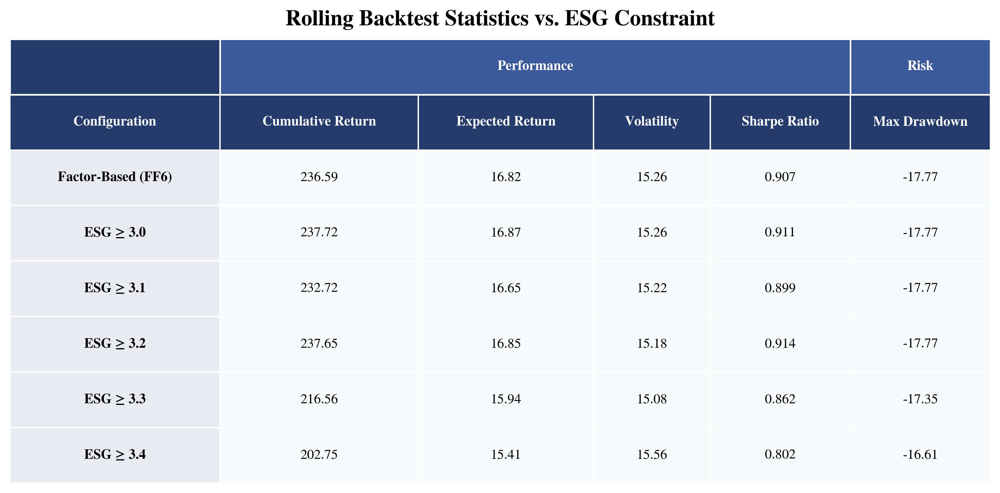

In [80]:
esg_bt_stats_formatted = format_portfolio_metrics(esg_bt_stats)

fig = plot_combined_metrics_table(
    esg_bt_stats_formatted,
    table_groups={
        "Performance": ["Cumulative Return", "Expected Return", "Volatility", "Sharpe Ratio"],
        "Risk": ["Max Drawdown"]
    },
    title="Rolling Backtest Statistics vs. ESG Constraint",
    index_label="Configuration"
)
fig.savefig("figures/esg_backtest_stats_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

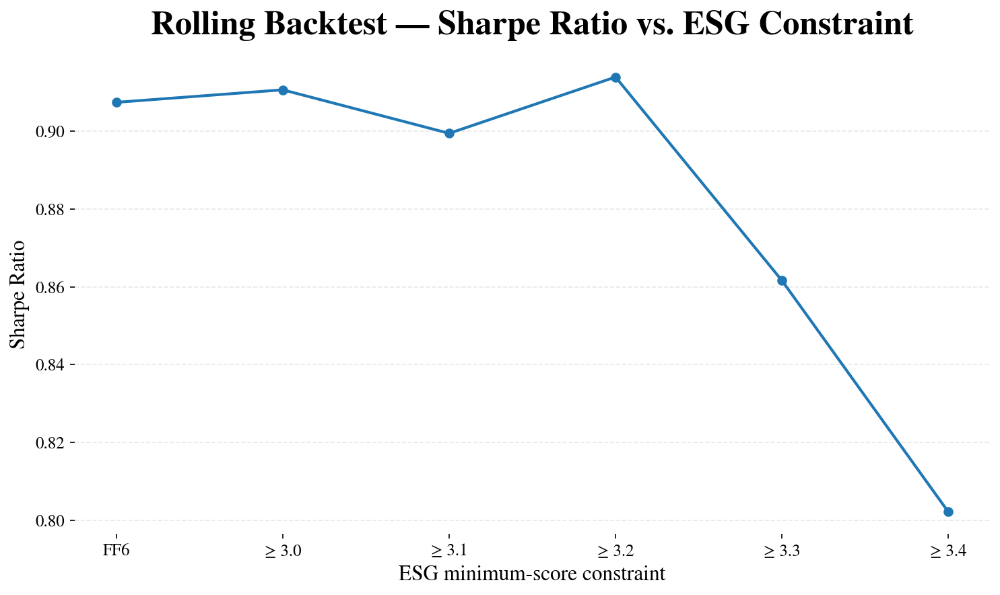

In [81]:
fig = plot_esg_sharpe_vs_constraint(esg_thresholds, esg_bt_stats["Sharpe Ratio"].values)
fig.savefig("figures/esg_backtest_sharpe.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

### Real-money translation of the ESG constraint

The backtest above measures the constraint's average cost over time; this closing illustration
makes it concrete on a single date. Starting from the final selected portfolio of Part 6-7 (FF6
expected returns, hybrid covariance at the retained $\lambda = 0.25$), we compare the unconstrained
baseline to the most demanding threshold still feasible under the 30% cap (ESG $\geqslant 3.4$), and
convert both into a real \$100,000 allocation — whole shares only, since an actual investor cannot
buy a fraction of a position.

In [82]:
esg_demo_threshold = 3.4

Sigma_lambda_025 = lambda_sigmas["0.25"]
w_baseline_demo = lambda_weights["0.25"]

w_esg_demo = build_optimized_portfolio(
    tickers=TICKERS,
    mu=mu_factor,
    Sigma=Sigma_lambda_025,
    risk_free_rate=risk_free_rate,
    name=f"ESG >= {esg_demo_threshold}",
    bounds=bounds,
    esg_scores=esg_scores,
    min_esg_score=esg_demo_threshold
)

demo_comparison = pd.DataFrame({
    "No ESG constraint": portfolio_summary(
        tickers=TICKERS, weights=w_baseline_demo.values, mu=mu_factor,
        Sigma=Sigma_lambda_025, risk_free_rate=risk_free_rate
    ),
    f"ESG >= {esg_demo_threshold}": portfolio_summary(
        tickers=TICKERS, weights=w_esg_demo.values, mu=mu_factor,
        Sigma=Sigma_lambda_025, risk_free_rate=risk_free_rate
    )
}).T

format_portfolio_metrics(demo_comparison)

,Expected Return,Volatility,Sharpe Ratio,HHI Normalized,Effective Number of Positions,Long Exposure,Short Exposure,Gross Exposure,Net Exposure
No ESG constraint,15.52,14.80,0.913,0.075,8.10,100.0,0.0,100.0,100.0
ESG >= 3.4,16.14,16.47,0.858,0.116,6.17,100.0,0.0,100.0,100.0


In [83]:
def real_money_allocation(weights, prices, amount):
    """
    Converts a weight vector into a whole-share allocation for a given amount
    invested: floors each position\'s dollar target to the nearest full share,
    since fractional shares are not purchasable in practice.
    """
    dollar_target = weights * amount
    shares = np.floor(dollar_target / prices).astype(int)
    invested = shares * prices
    table = pd.DataFrame({
        "Weight (%)": (weights * 100).round(2),
        "Price ($)": prices.round(2),
        "Shares": shares,
        "Invested ($)": invested.round(2)
    })
    return table[table["Shares"] > 0].sort_values("Invested ($)", ascending=False)

last_prices = prices.iloc[-1]

allocation_baseline = real_money_allocation(w_baseline_demo, last_prices, AMOUNT_INVESTED)
allocation_baseline

,Weight (%),Price ($),Shares,Invested ($)
KO,19.34,81.27,45,3657.15
PG,18.92,145.55,24,3493.28
JPM,14.23,325.86,8,2606.90
NVDA,9.53,199.87,9,1798.80
MSFT,8.55,372.32,4,1489.28
GOOGL,6.29,357.14,3,1071.42
AMZN,5.41,238.34,4,953.36
AAPL,5.08,289.11,3,867.33
HON,3.69,223.23,3,669.69
UNH,4.05,415.63,1,415.63


In [84]:
allocation_esg = real_money_allocation(w_esg_demo, last_prices, AMOUNT_INVESTED)
allocation_esg

,Weight (%),Price ($),Shares,Invested ($)
JNJ,29.60,252.72,22,5559.92
HON,14.36,223.23,12,2678.76
MSFT,14.87,372.32,7,2606.23
NVDA,10.60,199.87,10,1998.66
BAC,9.05,56.69,30,1700.72
AAPL,7.20,289.11,4,1156.44
GOOGL,6.72,357.14,3,1071.42
AMZN,4.09,238.34,3,715.02
PG,3.17,145.55,4,582.21


In [85]:
for label, w, table in [
    ("No ESG constraint", w_baseline_demo, allocation_baseline),
    (f"ESG >= {esg_demo_threshold}", w_esg_demo, allocation_esg)
]:
    invested = table["Invested ($)"].sum()
    leftover = AMOUNT_INVESTED - invested
    avg_esg = w @ esg_scores
    print(
        f"{label:14s} | {len(table):2d} positions | Invested ${invested:>10,.2f} | "
        f"Cash leftover ${leftover:>7,.2f} | Weighted-avg ESG {avg_esg:.3f}"
    )

No ESG constraint | 10 positions | Invested $ 17,022.84 | Cash leftover $2,177.16 | Weighted-avg ESG 2.989
ESG >= 3.4     |  9 positions | Invested $ 18,069.38 | Cash leftover $1,130.62 | Weighted-avg ESG 3.400


In [86]:
esg_demo_exposure = portfolio_exposure(w_esg_demo.values)
esg_demo_exposure

Long Exposure     1.0
Short Exposure    0.0
Gross Exposure    1.0
Net Exposure      1.0
dtype: float64

### Composite score vs. single-letter targeting

`make_min_esg_constraint` is agnostic to which score it is given — nothing ties it to the
blended ESG score specifically. This raises a natural question: does the blended score do
anything a single E, S, or G threshold wouldn't, or would targeting one letter directly work
just as well? Each sub-score is tested alone, at a threshold comparably demanding relative to
its own feasibility ceiling under the 30% cap: $E \geqslant 3.5$ (ceiling $3.85$),
$S \geqslant 3.5$ (ceiling $3.92$), $G \geqslant 4.0$ (ceiling $4.13$).

In [87]:
e_score = esg_summary["Environmental"]
s_score = esg_summary["Social"]
g_score = esg_summary["Governance"]

esg_letters_corr = esg_summary[["Environmental", "Social", "Governance"]].corr()
esg_letters_corr.round(3)

,Environmental,Social,Governance
Environmental,1.000,-0.195,-0.068
Social,-0.195,1.000,-0.163
Governance,-0.068,-0.163,1.000


In [88]:
w_e35 = build_optimized_portfolio(
    tickers=TICKERS, mu=mu_factor, Sigma=Sigma_lambda_025, risk_free_rate=risk_free_rate,
    name="E >= 3.5", bounds=bounds, esg_scores=e_score, min_esg_score=3.5
)
w_s35 = build_optimized_portfolio(
    tickers=TICKERS, mu=mu_factor, Sigma=Sigma_lambda_025, risk_free_rate=risk_free_rate,
    name="S >= 3.5", bounds=bounds, esg_scores=s_score, min_esg_score=3.5
)
w_g40 = build_optimized_portfolio(
    tickers=TICKERS, mu=mu_factor, Sigma=Sigma_lambda_025, risk_free_rate=risk_free_rate,
    name="G >= 4.0", bounds=bounds, esg_scores=g_score, min_esg_score=4.0
)

letters_comparison = {}
for label, w in [
    ("No ESG constraint", w_baseline_demo), (r"$E \geqslant 3.5$", w_e35), (r"$S \geqslant 3.5$", w_s35), (r"$G \geqslant 4.0$", w_g40)
]:
    row = portfolio_summary(
        tickers=TICKERS, weights=w.values, mu=mu_factor,
        Sigma=Sigma_lambda_025, risk_free_rate=risk_free_rate
    )
    row["ESG"] = w @ esg_scores
    row["E"] = w @ e_score
    row["S"] = w @ s_score
    row["G"] = w @ g_score
    letters_comparison[label] = row

letters_comparison = pd.DataFrame(letters_comparison).T
format_portfolio_metrics(letters_comparison)[
    ["Expected Return", "Volatility", "Sharpe Ratio", "Effective Number of Positions", "ESG", "E", "S", "G"]
].round(3)


,Expected Return,Volatility,Sharpe Ratio,Effective Number of Positions,ESG,E,S,G
No ESG constraint,15.52,14.80,0.913,8.10,2.989,2.860,2.596,3.570
$E \geqslant 3.5$,15.97,16.00,0.873,6.69,3.234,3.500,2.614,3.506
$S \geqslant 3.5$,16.03,15.90,0.882,6.37,3.144,2.879,3.500,3.494
$G \geqslant 4.0$,15.31,15.76,0.844,5.45,3.130,2.889,2.677,4.000


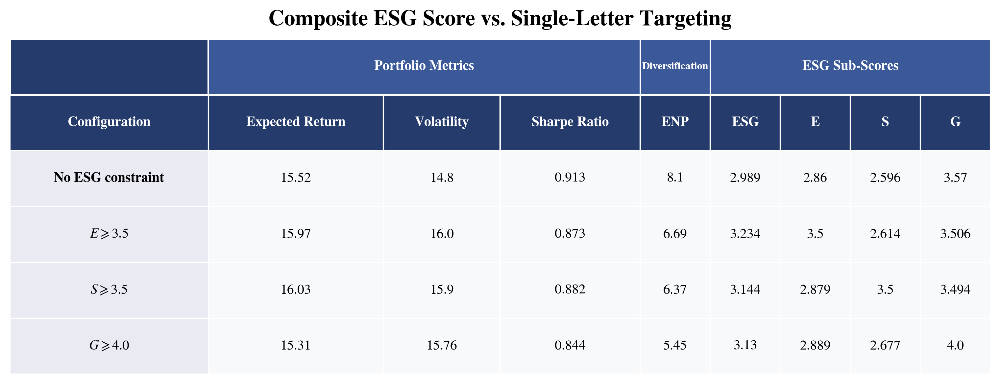

In [89]:
letters_comparison_formatted = format_portfolio_metrics(letters_comparison).round(3)

fig = plot_combined_metrics_table(
    letters_comparison_formatted,
    table_groups={
        "Portfolio Metrics": ["Expected Return", "Volatility", "Sharpe Ratio"],
        "Diversification": ["Effective Number of Positions"],
        "ESG Sub-Scores": ["ESG", "E", "S", "G"]
    },
    column_labels={"Effective Number of Positions": "ENP"},
    title="Composite ESG Score vs. Single-Letter Targeting",
    index_label="Configuration"
)
fig.savefig("figures/esg_letters_comparison_table.png", dpi=300, bbox_inches="tight")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

# Part: Opening on crypto-assets

This section is purely descriptive - no portfolio is built here. Its purpose is to illustrate,
with real data, the reasoning already laid out for why
Bitcoin and Ethereum were excluded from the investable universe: a risk profile (volatility,
drawdowns) structurally incompatible with the rest of the universe, and no reliable implied-volatility
history over the full study window (Deribit's DVOL only starts in 2021).

In [90]:
crypto_prices = load_or_fetch_prices(CRYPTO_TICKERS, START_DATE, END_DATE, CRYPTO_PRICES_SNAPSHOT_PATH)
crypto_returns = crypto_prices.pct_change()

for ticker in CRYPTO_TICKERS:
    r = crypto_returns[ticker].dropna()
    print(f"{ticker}: {r.index[0].strftime('%Y-%m')} to {r.index[-1].strftime('%Y-%m')} ({len(r)} months)")


Prices loaded from frozen snapshot (Price snapshot retrieved on 2026-09-12 (start=2015-01-01, end=2026-06-30))
BTC-USD: 2015-02 to 2026-06 (137 months)
ETH-USD: 2017-12 to 2026-06 (103 months)


## Cumulative performance

Growth of $\$1$ invested at each asset's own first available date (BTC-USD from the start of the
study period; ETH-USD only from November $2017$, its earliest available monthly close). Plotted on
a log scale.

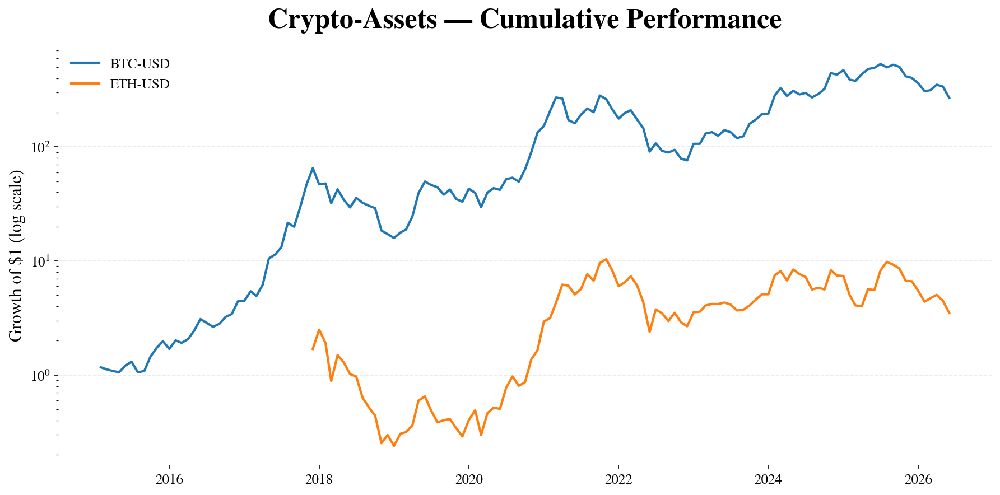

In [91]:
crypto_growth = pd.DataFrame({
    ticker: (1 + crypto_returns[ticker]).cumprod()
    for ticker in CRYPTO_TICKERS
})

fig = plot_cumulative_performance(crypto_growth, "Crypto-Assets — Cumulative Performance")
fig.savefig("figures/crypto_cumulative_performance.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## Drawdown

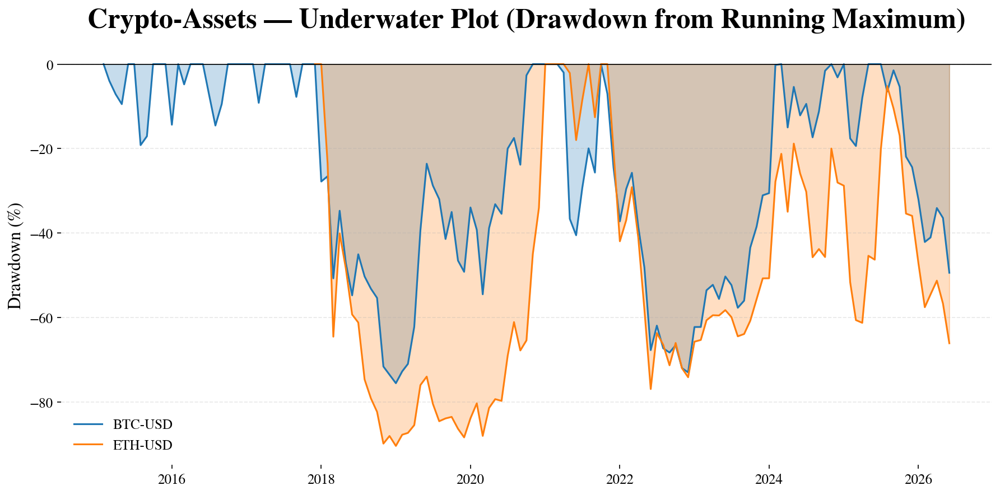

In [92]:
crypto_drawdowns = pd.DataFrame({
    ticker: drawdown_series(crypto_returns[ticker].dropna()) * 100
    for ticker in CRYPTO_TICKERS
})

fig = plot_underwater_by_asset(crypto_drawdowns, "Crypto-Assets — Underwater Plot (Drawdown from Running Maximum)")
fig.savefig("figures/crypto_underwater_plot.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

In [93]:
for ticker in CRYPTO_TICKERS:
    r = crypto_returns[ticker].dropna()
    ann_return = (1 + r.mean()) ** FREQUENCY - 1
    ann_vol = r.std() * np.sqrt(FREQUENCY)
    max_dd = max_drawdown(r) * 100
    start_label = r.index[0].strftime("%Y-%m")
    end_label = r.index[-1].strftime("%Y-%m")
    print(f"{ticker:10s} | {start_label} to {end_label} | "
          f"Return {ann_return*100:8.2f}% | Vol {ann_vol*100:7.2f}% | Max Drawdown {max_dd:7.2f}%")


BTC-USD    | 2015-02 to 2026-06 | Return   103.38% | Vol   71.40% | Max Drawdown  -75.57%
ETH-USD    | 2017-12 to 2026-06 | Return    72.97% | Vol   95.13% | Max Drawdown  -90.43%


# Part: Opening on diversification candidates (bonds, gold, REITs)

In [94]:
diversification_prices = load_or_fetch_prices(DIVERSIFICATION_TICKERS, START_DATE, END_DATE, DIVERSIFICATION_PRICES_SNAPSHOT_PATH)
diversification_returns = diversification_prices.pct_change()

for ticker in DIVERSIFICATION_TICKERS:
    r = diversification_returns[ticker].dropna()
    print(f"{ticker}: {r.index[0].strftime('%Y-%m')} to {r.index[-1].strftime('%Y-%m')} ({len(r)} months)")


Prices loaded from frozen snapshot (Price snapshot retrieved on 2026-09-12 (start=2015-01-01, end=2026-06-30))
TLT: 2015-02 to 2026-06 (137 months)
GLD: 2015-02 to 2026-06 (137 months)
VNQ: 2015-02 to 2026-06 (137 months)


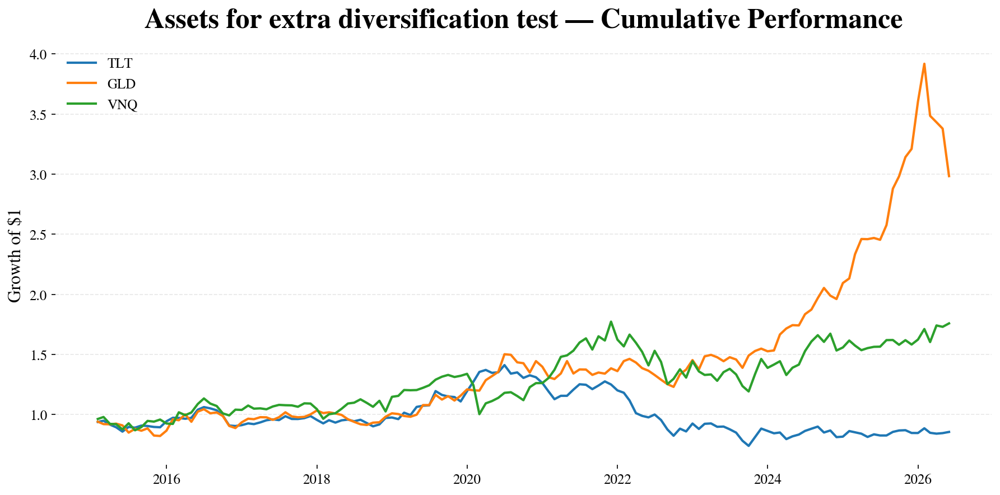

In [95]:
diversification_growth = pd.DataFrame({
    ticker: (1 + diversification_returns[ticker]).cumprod()
    for ticker in DIVERSIFICATION_TICKERS
})

fig = plot_cumulative_performance(diversification_growth, f"Assets for extra diversification test — Cumulative Performance", log_scale=False)
fig.savefig("figures/diversification_cumulative_performance.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

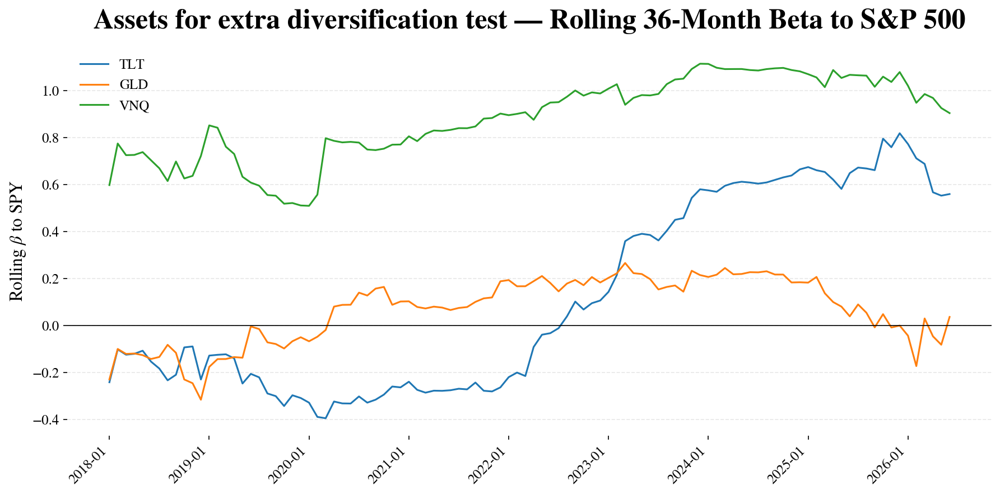

In [96]:
ROLLING_BETA_WINDOW = 36

diversification_returns_period = diversification_returns.copy()
diversification_returns_period.index = pd.to_datetime(diversification_returns_period.index).to_period("M")
diversification_aligned = diversification_returns_period.reindex(spy_returns.index).dropna(how="all")

rolling_beta = pd.DataFrame(index=diversification_aligned.index, columns=DIVERSIFICATION_TICKERS, dtype=float)
for ticker in DIVERSIFICATION_TICKERS:
    pair = pd.concat([diversification_aligned[ticker], spy_returns], axis=1).dropna()
    pair.columns = ["asset", "spy"]
    cov = pair["asset"].rolling(ROLLING_BETA_WINDOW).cov(pair["spy"])
    var = pair["spy"].rolling(ROLLING_BETA_WINDOW).var()
    rolling_beta.loc[pair.index, ticker] = (cov / var).values

fig = plot_rolling_beta(rolling_beta, ROLLING_BETA_WINDOW)
fig.savefig("figures/diversification_rolling_beta.png", dpi=300, bbox_inches="tight")

if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

In [97]:
for ticker in DIVERSIFICATION_TICKERS:
    r = diversification_returns[ticker].dropna()
    ann_return = (1 + r.mean()) ** FREQUENCY - 1
    ann_vol = r.std() * np.sqrt(FREQUENCY)
    r_period = diversification_returns_period[ticker].dropna()
    pair = pd.concat([r_period, spy_returns], axis=1).dropna()
    pair.columns = ["asset", "spy"]
    beta_full = pair["asset"].cov(pair["spy"]) / pair["spy"].var()
    corr_full = pair["asset"].corr(pair["spy"])
    start_label = r.index[0].strftime("%Y-%m")
    end_label = r.index[-1].strftime("%Y-%m")
    print(f"{ticker:6s} | {start_label} to {end_label} | "
          f"Return {ann_return*100:7.2f}% | Vol {ann_vol*100:6.2f}% | "
          f"Beta(SPY) {beta_full:6.3f} | Corr(SPY) {corr_full:6.3f}")

TLT    | 2015-02 to 2026-06 | Return   -0.50% | Vol  13.26% | Beta(SPY)  0.120 | Corr(SPY)  0.136
GLD    | 2015-02 to 2026-06 | Return   11.34% | Vol  15.48% | Beta(SPY)  0.089 | Corr(SPY)  0.086
VNQ    | 2015-02 to 2026-06 | Return    6.68% | Vol  17.45% | Beta(SPY)  0.873 | Corr(SPY)  0.754
